In [1]:
#conda install -c numba/label/dev numba

In [2]:
import numpy as np
from typing import Tuple
from scipy.optimize import linear_sum_assignment
from numba import njit, set_num_threads
from scipy.sparse.linalg import lobpcg
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import loompy
from sklearn.svm import SVR
import pickle
import scipy.sparse as ss
import math
from sklearn.neighbors import NearestNeighbors
from numpy import savetxt
from typing import Dict
import anndata as ad
from numpy.random import randint
from numpy.random import seed
import numba
import time
import statistics
from scipy.linalg import svd
from sklearn.decomposition import PCA

In [3]:
from threadpoolctl import threadpool_limits
threadpool_limits(limits=6)



class TimerError(Exception):
    """A custom exception used to report errors in use of Timer class"""

class Timer:
    def __init__(self):
        self._start_time = None
        self.msg = None

    def start(self, msg=""):
        """Start a new timer"""
        self.msg = msg
        if self._start_time is not None:
            raise TimerError(f"Timer is running. Use .stop() to stop it")

        self._start_time = time.perf_counter()

    def stop(self):
        """Stop the timer, and report the elapsed time"""
        if self._start_time is None:
            raise TimerError(f"Timer is not running. Use .start() to start it")

        elapsed_time = time.perf_counter() - self._start_time
        self._start_time = None
        print(f"{self.msg} Elapsed time: {elapsed_time:0.4f} seconds")




In [4]:

#sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
#sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(3, 3), facecolor='white')


In [5]:
def plotP(rng, Xa, Xb, A, B, P, labels_a=None, labels_b=None, show_fraction=1, alpha=0.5):
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    plt.figure(None,(15,7))
    delta = 2 * np.sqrt( np.linalg.svd(Xa, compute_uv=False)[0] )
    if labels_a is not None:
        plt.scatter(Xa[:, 0], Xa[:, 1], c=labels_a, cmap="tab10")
    else:
        plt.scatter(Xa[:, 0], Xa[:, 1])
    
    if labels_b is not None:
        plt.scatter(Xb[:, 0]+delta, Xb[:, 1], c=labels_b, cmap="tab10")
    else:
        plt.scatter(Xb[:, 0]+delta, Xb[:, 1])
    p = np.where(P)[1]
    for i in rng.choice(Xa.shape[0], size=int(np.ceil(show_fraction*Xa.shape[0])), replace=False):
        plt.plot([Xa[i, 0], Xb[p[i], 0]+delta], [Xa[i, 1], Xb[p[i], 1]], c=(0.7,0.7,0.7, alpha))
    plt.axis("equal")
    plt.axis("off")
        


@njit(parallel=True)
def normF(M):
    cumulant = 0.0
    for i in numba.prange(M.shape[0]):
        for j in range(M.shape[1]):
            cumulant += M[i,j]**2
    return np.sqrt(cumulant)

@njit(parallel=True)
def normF2(M):
    cumulant = 0.0
    for i in numba.prange(M.shape[0]):
        for j in range(M.shape[1]):
            cumulant += M[i,j]**2
    return cumulant

def score_latent(P, YA, YB, k=10):
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(YB)
    neigh_dist, neigh_ind = nn.kneighbors(YA)
    score = 0
    maxscore = 0
    for i in range(neigh_ind.shape[0]):
        for j in neigh_ind[i, :]:
            score += P[i, j]
    return score / P.shape[0]

def score_neigh(Ya, Yb, P, P0, k=10):
    #adj_a = compute_adjaciency_matrix(Ya, n_neighbors=k)
    adj_b = compute_adjaciency_matrix(Yb, n_neighbors=k)
    count = 0.0
    for i in range(adj_b.shape[0]):
        count += np.any(P @ adj_b[i, :] * P0[:,i])
    return count / Ya.shape[0]

score = score_latent

def randPSD_old(rng, size=2, eigrange=(0.2,5)):
    cov = np.zeros((size, size))
    eigvector_candidates = []
    eigvalues = np.zeros(size)
    
    # draw eigenvalues and candidate eigenvectors (unit vectors)
    for i in range(size):
        candidate = rng.random(size=size)
        candidate = candidate / np.linalg.norm(candidate)
        eigvector_candidates.append(candidate)
        eigvalues[i] = rng.uniform(*eigrange, size=1)
    
    # make candidates an orthogonal set
    for i in range(1, size):
        candidate = eigvector_candidates[i]
        for other in eigvector_candidates[:i]:
            projection_on_other = other * candidate.dot(other) / np.linalg.norm(other)
            candidate = candidate - projection_on_other
            candidate = candidate / np.linalg.norm(candidate) # renormalize
        eigvector_candidates[i] = candidate
    eigenvectors = np.column_stack(eigvector_candidates)
    if np.allclose(eigenvectors @ eigenvectors.T, np.eye(size)):
        return eigenvectors.T * eigvalues @ eigenvectors
    else:
        print(eigenvectors)
        return eigenvectors
    
def randPSD(rng, size=2, eigrange=(0.2, 5)):
    if isinstance(eigrange, tuple):
        L = rng.normal(0, 1, size=(size, size))
        #L = L / np.linalg.norm(L, axis=1)[:, None]
        _, _, eigvects = np.linalg.svd(L, full_matrices=False)
        eigvals = rng.uniform(eigrange[0], eigrange[1], size=size)
        M = eigvects.T * eigvals @ eigvects
    else:
        L = rng.normal(0, 1, size=(size, size))
        _, _, eigvects = np.linalg.svd(L, full_matrices=False)
        eigvals = rng.uniform(np.array(eigrange_list)[:,0], np.array(eigrange_list)[:,1],
                                    size=size)
        M = eigvects.T * eigvals @ eigvects
    return M

    
def perm2P(p):
    shape = len(p)
    P = np.zeros((shape,shape), dtype=int)
    for i in range(shape):
        P[i, p[i]] = 1
    return P


def make_random_P(rng, shape):
    #p = np.random.permutation(shape)
    p = rng.permutation(shape)
    P = perm2P(p)
    return P      


def lapjv(X):
    return linear_sum_assignment(X)[1]


@njit
def vector_th_alpha_beta(a, b, Lambda):
    dims = a.shape
    numdims = len(a.shape)
    dimy = dims[0]
    dimx = dims[1]

    c = np.zeros((dimy,dimx), dtype=np.float32)
    d = np.zeros((dimy,dimx), dtype=np.float32)

    for i in range(dimx):
        for j in range(dimy):
            norm = np.sqrt(a[i, j]**2 + b[i, j]**2)
            if (norm > 0):
                c[i, j] = np.maximum(0.0, 1.0 - Lambda/norm) * a[i, j]
                d[i, j] = np.maximum(0.0, 1.0 - Lambda/norm) * b[i, j]
    return c, d


def perm2mat(p: np.ndarray) -> np.ndarray:
    n = len(p)
    P = np.zeros((n, n))
    for k in range(n):
        P[k, p[k]] = 1
    return P


def admom_sub_solve_for_alpha_beta(A, B, P, U, W, c):
    """Solve for alpha and bet using ADMM

    Method from:
    Robust Multimodal Graph Matching: Sparse Coding Meets Graph Matching
    Advances in Neural Information Processing Systems 26 (NIPS 2013)
    M. Fiori, P. Sprechmann, J. Vogelstein, P. Musé, G. Sapiro
    """

    C = A @ P - U
    D = P @ B - W
    #alpha, beta = vector_th_alpha_beta(C.astype(float), D.astype(float), 1.0 / c)
    alpha, beta = vector_th_alpha_beta(C.astype(float), D.astype(float), 1.0 / (c+1e-10))
    return alpha, beta

@numba.njit
def project_DS(Ti: np.ndarray, tol: float = 1e-5) -> np.ndarray:
    n = Ti.shape[0]

    var = 1
    Jn = 1 / n
    xk = Ti

    iter_ = 0
    max_iter = 200
    while (var > tol) and (iter_ < max_iter):
        iter_ = iter_ + 1
        xkold = xk
        yk = xk - (xk.sum(0) / xk.shape[1])
        yk = yk - (yk.sum(1).reshape((-1,1)) / xk.shape[0] - Jn)
        # yk = W @ xk @ W + Jn
        xk = np.maximum(0, yk)
        var = np.sum(np.abs(xk - xkold))
    return xk



def admom_sub_solve_for_P_linearized(alpha, beta, A, B, U, W, tau, Pk, tole=1e-5):
    C = alpha + U
    D = beta + W

    f = np.sum((C - A @ Pk) ** 2) + np.sum((D - Pk @ B) ** 2)  # Frobenius squared
    f2 = f + 1

    k = 0
    while (f2 > f) and (k < 10):
        k = k + 1
        R1 = Pk + tau*A.T @ (C - A @ Pk) / k
        R2 = Pk + tau*(D - Pk @ B) @ B.T / k

        P = project_DS((R1 + R2) / 2, tole)
        f2 = np.sum((C - A @ P) ** 2) + np.sum((D - P @ B) ** 2)

    return P


def admom_sub_solve_for_P_onestep(alpha,  beta, A, B, U, W, Pk):
    C = alpha + U
    D = beta + W

    f = np.sum((C - A @ Pk) ** 2) + np.sum((D - Pk @ B) ** 2)

    eta = 0.7
    max_iter_in = 50
    N = 5
    step = 1
    grad = A.T @ (C - A @ Pk) + (D - Pk @ B) @ B.T

    notGoodEnough = True
    iter_in = 0

    while (notGoodEnough) and (iter_in < max_iter_in):
        iter_in = iter_in + 1
        P1 = Pk + step * grad
        P2 = project_DS(P1)

        for i in range(1, N+1):
            a = 1.0 / i
            Pc = (1 - a) * Pk + a * P2
            fc = np.sum((C - A * Pc) ** 2) + np.sum((D - Pc * B) ** 2)
            if fc < f:
                P2 = Pc
                notGoodEnough = False
                break
        step = step * eta

    return P2


def graph_matching(
    A: np.ndarray,
    B: np.ndarray,
    *,
    c: float = 2.0,
    tol: float = 2e-2,
    tol2: float = 9e-9,
    N: int = 100,
    maxIter: int = 30000,
    verbose: bool = False
) -> Tuple[np.ndarray, np.ndarray]:
    """Compute a graph matching

    Parameters
    ----------
        A: np.ndarray
            Adjacency matrix of the first graph to be matched

        B: np.ndarray
            Adjacency matrix of the first graph to be matched

        c: float = 2
            Parameter c in the optimization. It doesn't affect the convergence.

        tol: float = 2e-2
            Tolerance in the difference of the objective function.

        tol2: float = 9e-9
            Tolerance in Frobenius norm of AP-PB

        N: int = 100
            Computes the closest permuation matrix after each N iterations

        maxIter: int = 30000

        verbose: bool = False

    Outputs
    -------
        P: np.ndarray
            doubly stochastic matrix minimizing the objective function
        Pp: np.ndarray
            best permutation matrix found
    """

    p = A.shape

    def forig(P: np.ndarray) -> float:
        return np.sum(np.sqrt((A @ P) ** 2 + (P @ B) ** 2))

    P = np.ones(p) / p[0]
    U = np.zeros(p)
    W = np.zeros(p)

    iter_ = 0

    rhoA = np.max(np.linalg.eigh(A.T @ A)[0])  # Consider doing this by SVD
    rhoB = np.max(np.linalg.eigh(B.T @ B)[0])
    rho = max(rhoA, rhoB)
    tau = 0.8 / rho

    var = 1.0
    normAPPB = 1.0
    normAPPB1 = 1.0
    fori = 1.0

    Pmin = P
    fmin = 1e10
    zigzag1 = 0
    Nzigzag = 10.0

    forigi = []

    while (normAPPB > tol) and (normAPPB1 > tol) and (var > tol2) and (iter_ < maxIter):
        if verbose and iter_ % min([50, N]) == 0:
            print(f"Iteration #{iter_}", end=", ")
        iter_ = iter_ + 1
        normAPPB_o = normAPPB
        Pold = P
        fori_o = fori

        # Solve for alpha and beta
        alpha, beta = admom_sub_solve_for_alpha_beta(A, B, P, U, W, c)

        # Solve for P
        tole = 1e-4
        if zigzag1 > Nzigzag:
            P = admom_sub_solve_for_P_onestep(alpha, beta, A, B, U, W, P)
            zigzag1 = 0
            Nzigzag = Nzigzag * 1.2
        else:
            P = admom_sub_solve_for_P_linearized(alpha, beta, A, B, U, W, tau, P, tole)
        # Update
        U = U + alpha - A @ P
        W = W + beta - P @ B

        fori = forig(P)

        # Each N iterations, compute the closest permutation matrix and check
        # if it gives a perfect match
        if iter_ % N == 0:
            if verbose:
                print("Compute permutation")
            corr = lapjv(-P)
            P1 = perm2mat(corr)
            normAPPB1 = np.sqrt(np.sum((A @ P1 - P1 @ B) ** 2))  # Frobenius norm
            fau = forig(P1)
            if fau < fmin:
                fmin = fau
                Pmin = P1

        forigi.append(fori)
        
        # if the optimization gets stuck, reinitialize with the identity matrix (maybe should be with a random permutation)
        if iter_ > 5:
            normAPPB = np.sqrt(np.sum((A @ P - P @ B) ** 2))  # Frobenius norm
            var = 100 #np.abs(normAPPB - normAPPB_o) # + np.abs(fori - fori_o) + 
            #var = var / normAPPB_o
            zigzag = (
                  (forigi[iter_ - 3] < forigi[iter_ - 2])
                * (forigi[iter_ - 3] < forigi[iter_ - 4])
                * (forigi[iter_ - 1]     < forigi[iter_ - 2])
                * (forigi[iter_ - 5] < forigi[iter_ - 4])
                * (forigi[iter_ - 5] < forigi[iter_ - 6])
            )
            zigzag1 = zigzag1 + zigzag

            if iter_ == 6 and var < 1e-7: # I do not understand why iter_ == 6!
                var = 1
                P = np.eye(p) # May
                if verbose:
                    print(f"Reinitialized to the indetity")
                    
        if verbose and not ((normAPPB > tol) and (normAPPB1 > tol) and (var > tol2) and (iter_ < maxIter)):
            if not (normAPPB > tol):
                print(f"normAPPB at {normAPPB}")
                print(f"Terminating at {iter_} for tol (APPB)")
            if not (normAPPB1 > tol):
                print(f"Terminating at {iter_} for tol (APPB1)")
            if not (var > tol2):
                print(f"Terminating at {iter_} for tol2 = {var}")
            if not (iter_ < maxIter):
                print(f"Terminating at {iter_} for maxiter")
    
    # Final check
    corr = lapjv(-P)
    Pp = perm2mat(corr)
    fau = forig(Pp)
    # update minimum if improved
    if fmin < fau:
        fau = fmin
        Pp = Pmin
        
    return P, Pp



## Graph Matching with Gene Activity as the prior information

In [6]:

@numba.njit(parallel=True)
def admom_sub_solve_for_P_linearized_withD(c1, c2, D_GA, X_A, X_B, W, alpha, beta, A, B, U, V, tau, Pk, tole=1e-5):
    w = np.diag(W)
    C = alpha + U
    D = beta + V
    E = X_B * w @ D_GA

    CmAPk = C - A @ Pk
    DmPkB = D - Pk @ B
    XAmPkE = X_A - Pk @ E
    set_num_threads(6)
    f = c1 / 2 * normF2(CmAPk) + c1 / 2 * normF2(DmPkB) + c2 * normF2(XAmPkE)  # Frobenius squared
    f2 = f + 1

    k = 1
    plus1 = tau * A.T @ (CmAPk) 
    plus2 = tau * (DmPkB) @ B.T 
    plus3 = tau * (XAmPkE) @ E.T
    
    # The code below takes 40% of the time of this function
    while (f2 > f) and (k < 11):
        R1 = Pk + plus1 / k
        R2 = Pk + plus2 / k
        R3 = Pk + plus3 / k
        P = project_DS((c1 / 2  * R1 + c1 / 2 * R2 + c2 * R3) / (c1+c2), tole)
        f2 = c1 / 2 * np.sum((C - A @ P) ** 2) + c1 / 2 * np.sum((D - P @ B) ** 2) + c2 * np.sum((X_A - P @ E) ** 2)
        k = k + 1
        
    return P


def admom_sub_solve_for_P_onestep_withD(c1, c2, D_GA, X_A, X_B, W, alpha, beta, A, B, U, V, Pk):
    C = alpha + U
    D = beta + V
    E = X_B @ W @ D_GA

    CmAPk = C - A @ Pk
    DmPkB = D - Pk @ B
    XAmPkF = X_A - Pk @ E
    set_num_threads(6)
    f = c1 / 2 * normF2(CmAPk) + c1 / 2 * normF2(DmPkB) + c2 * normF2(XAmPkF)

    eta = 0.7
    max_iter_in = 50
    N = 5
    step = 1
    grad = c1 * A.T @ (CmAPk) + c1 * (DmPkB) @ B.T + 2 * c2 * (XAmPkF) @ E.T

    notGoodEnough = True
    iter_in = 0

    while (notGoodEnough) and (iter_in < max_iter_in):
        iter_in = iter_in + 1
        P1 = Pk + step * grad
        P2 = project_DS(P1)

        for i in range(1, N+1):
            a = 1.0 / i
            Pc = (1 - a) * Pk + a * P2
            set_num_threads(6)
            fc = c1 / 2 * normF2(C - A @ Pc) + c1 / 2 * normF2(D - Pc @ B) + c2 * normF2(X_A - Pc @ E)
            if fc < f:
                P2 = Pc
                notGoodEnough = False
                break
        step = step * eta

    return P2

def admom_sub_solve_for_w_onestep_withD(c2, c3, c4, D, X_A, X_B, W, P):
    
    w = np.diag(W)
    E = X_B * w @ D
    #Gioele
    set_num_threads(6)
    f = c2* normF2(X_A - P @ E) + c3 * np.sum(w ** 2) - c4 * np.sum(np.log( np.maximum(w, 1e-15)))
    eta = 0.7
    max_iter_in = 100
    N = 5
    step = 0.00001
    [peaks,genes] = D.shape
    grad_w = []
    #Grad_matrix = (- D @ X_A.T @ P @ X_B - X_B.T @ P.T @ X_A @ D.T + X_B.T @ P.T @ P @ X_B @ W @ D @ D.T + D @ D.T @ W @ X_B.T @ P.T @ P @ X_B)
    P_XB = P @ X_B
    D_DT = D @ D.T
    XA_DT = X_A @ D.T
    # PXBT_XADT = (P_XB).T @ XA_DT
    diagPXBT_XADT = np.sum(P_XB * XA_DT, 0)
    PXBT_PXB = (P_XB).T @ P_XB # Note == PXBT_PXB.T
    WD_DT = D_DT * w[:, None] # W @ D_DT
    #PXBTPXB_WDDT = PXBT_PXB @ WD_DT
    diagPXBTPXB_WDDT = np.sum(PXBT_PXB.T * WD_DT, 0)
    #Grad_matrix = (- PXBT_XADT.T - PXBT_XADT \
    #               + PXBTPXB_WDDT + PXBTPXB_WDDT.T) 
    # ! Noticing that the diagonal elements are equal
    diagGrad_matrix = -2* diagPXBT_XADT + 2 * diagPXBTPXB_WDDT
    # Noticing that to get the diagonal element one does not need the last matrix multiplications
    
    #Gioele
    grad_w = c2 * diagGrad_matrix + 2 * c3 * w + c4 / np.maximum(w, 1e-15)
        
    notGoodEnough = True
    iter_in = 0

    while (notGoodEnough) and (iter_in < max_iter_in):
        iter_in = iter_in + 1
        #W1 = W - step * np.diag(grad_w)
        w1 = w - step * grad_w
        
        for i in range(1, N+1):
            a = 1.0 / i
            wc = (1 - a) * w + a * w1
            Ec = X_B * wc @ D
            set_num_threads(6)
            fc = c2* normF2(X_A - P @ Ec) + c3 * np.sum(wc** 2) - c4 * np.sum(np.log( np.maximum(wc, 1e-15)))
            if fc < f:
                w1 = wc
                notGoodEnough = False
                break
        step = step * eta
    return w1

def graph_matching_withD(
    D_GA: np.ndarray,
    X_A: np.ndarray,
    X_B: np.ndarray,
    A: np.ndarray,
    B: np.ndarray,
    *,
    c1: float = 2.0,
    c2: float = 1.0,
    c3: float = 1.0,
    c4: float = 1.0,
    tol: float = 2e-2,
    tolbar: float = 1e-4,
    tol2: float = 9e-9,
    N: int = 100,
    maxIter: int = 30000,
    verbose: bool = False
) -> Tuple[np.ndarray, np.ndarray]:
    """Compute a graph matching

    Parameters
    ----------
        c1: Parameter c1 in the optimization.

        c2: Parameter c2 in the optimization.
        
        c3: Parameter c2 in the optimization.
        
        c4: Parameter c2 in the optimization.

        D_GA: np.ndarray
            Gene Activity matrix of size Peak * Genes

        X_A: RNA matrix of the size cells * genes

        X_B: ATAC matrix of the size cells * peaks

        A: np.ndarray
            Adjacency matrix of the first graph to be matched

        B: np.ndarray
            Adjacency matrix of the first graph to be matched

        tol: float = 2e-2
            Tolerance in the difference of the objective function.
            
        tol: float = 1e-4
            Tolerance for the non negative constraints.

        tol2: float = 9e-9
            Tolerance in Frobenius norm of AP-PB

        N: int = 100
            Computes the closest permuation matrix after each N iterations

        maxIter: int = 30000

        verbose: bool = False

    Outputs
    -------
        P: np.ndarray
            doubly stochastic matrix minimizing the objective function
        Pp: np.ndarray
            best permutation matrix found
    """
    tm = Timer()
    tglobal = Timer()
    D_GA = D_GA.astype(float)
    
    p = A.shape
    [peaks,genes] = D_GA.shape
    #Gioele
    def forig(P: np.ndarray, w: np.ndarray) -> float:
        return c1 * np.sum(np.sqrt((A @ P) ** 2 + (P @ B) ** 2)) + c2 * np.sum((X_A - P @ X_B * w @ D_GA) ** 2)+ c3 * np.sum(w ** 2)
    
    P = np.ones(p) / p[0]
    U = np.zeros(p)
    V = np.zeros(p)
    w = np.ones(peaks)

    iter_ = 0

    rhoA = np.max(np.linalg.eigh(A.T @ A)[0])  # Consider doing this by SVD
    rhoB = np.max(np.linalg.eigh(B.T @ B)[0])

    var = 1.0
    normAPPB = 1.0
    normAPPB1 = 1.0
    SecondTerm = 1.0
    SecondTerm1 = 1.0
    fori = 1.0

    Pmin = P
    fmin = 1e10
    zigzag1 = 0
    Nzigzag = 10.0
    #Gioele
    barrier_term = +np.inf

    forigi = []
    while not stop_condition(normAPPB, normAPPB1, barrier_term, iter_, tol, tolbar, maxIter):
        #tglobal.start(f"\nIteration {iter_}")
        #if verbose and iter_ % min([50, N]) == 0:
        #    print(f"Iteration #{iter_}", end=", ")
        iter_ = iter_ + 1
        normAPPB_o = normAPPB
        Pold = P
        fori_o = fori

        # Solve for alpha and beta
        #tm.start("admom_sub_solve_for_alpha_beta")
        alpha, beta = admom_sub_solve_for_alpha_beta(A, B, P, U, V, c1)
        #tm.stop()

        # Solve for P
        tole = 1e-4
        if zigzag1 > Nzigzag:
            #tm.start("admom_sub_solve_for_P_onestep_withD")
            P = admom_sub_solve_for_P_onestep_withD(c1, c2, D_GA, X_A, X_B, np.diag(w), alpha, beta, A, B, U, V, P)
            #tm.stop()
            zigzag1 = 0
            Nzigzag = Nzigzag * 1.2
        else:
            #tm.start("prepare solve P")
            E = X_B @ np.diag(w) @ D_GA
            rhoE = np.max(np.linalg.eigh(E.T @ E)[0])
            rho = max(rhoA, rhoB, rhoE)
            tau = 0.8 / rho
            #tm.stop()
            #tm.start("admom_sub_solve_for_P_linearized_withD")
            set_num_threads(6)
            P = admom_sub_solve_for_P_linearized_withD(c1, c2, D_GA, X_A, X_B, np.diag(w), alpha, beta, A, B, U, V, tau, P, tole)
            #tm.stop()
        
        # Solve for w
        #tm.start("admom_sub_solve_for_w_onestep_withD")
        if c2 > 0:
            w = admom_sub_solve_for_w_onestep_withD(c2, c3, c4, D_GA, X_A, X_B, np.diag(w), P)
        #w=np.ones(peaks)
        #tm.stop()
        
        # Update
        #tm.start("update and check")
        U = U + alpha - A @ P
        V = V + beta - P @ B
        fori = forig(P, w)
        #tm.stop()

        # Each N iterations, compute the closest permutation matrix and check
        # if it gives a perfect match
        if (iter_-1) % N == 0:
            if verbose:
                F1=c1 * np.sum(np.sqrt((A @ P) ** 2 + (P @ B) ** 2)) 
                F2=c2 * np.sum((X_A - P @ X_B @ np.diag(w) @ D_GA) ** 2)
                F3=c3 * np.sum(np.diag(w) ** 2)
                F4= - c4 * np.sum(np.log(np.maximum(w, 1e-15)))
                
                #c1 = iter_*c1
                #c2 = c2+iter_*0.01
                #c3 = iter_*c3
                #c4 = iter_*c4
                #print(f"Iteration #{iter_},normAPPB={iter_},SecondTerm={SecondTerm},normAPPB1={iter_},SecondTerm1={SecondTerm1}", end=",")
                print(f"Iteration #{iter_},F1={F1},F2={F2},F3={F3},F4={F4}", end=",")
                print(" ")
                
            corr = lapjv(-P)
            P1 = perm2mat(corr)
            FirstTerm1 = np.sqrt(np.sum((A @ P1 - P1 @ B) ** 2))
            SecondTerm1 = np.sum((X_A - P1 @ X_B @ np.diag(w) @ D_GA) ** 2)
            normAPPB1 = c1 * FirstTerm1 + c2 * SecondTerm1 + c3 * np.sum(w ** 2)  # Barrier term was removed
            barrier_term = -c4 * np.sum(np.log( np.maximum(w, 1e-15)))
            fau = forig(P1, w)
            if fau < fmin:
                fmin = fau
                Pmin = P1

        forigi.append(fori)
        
        # if the optimization gets stuck, reinitialize with the identity matrix (maybe should be with a random permutation)
        if iter_ > 5:
            #tm.start("zig zag procedure")
            set_num_threads(6)
            FirstTerm = normF(A @ P - P @ B)
            SecondTerm = normF2(X_A - P @ X_B * w @ D_GA)
            normAPPB = c1 * FirstTerm + c2 * SecondTerm + c3 * np.sum(w ** 2) # Barrier term was removed
            barrier_term = -c4 * np.sum(np.log(np.maximum(w, 1e-15))) # Add the maximum, to avoid nan but allow infinity
            
            var = 100 #np.abs(normAPPB - normAPPB_o) # + np.abs(fori - fori_o) + 
            #var = var / normAPPB_o
            zigzag = (
                  (forigi[iter_ - 3] < forigi[iter_ - 2])
                * (forigi[iter_ - 3] < forigi[iter_ - 4])
                * (forigi[iter_ - 1]     < forigi[iter_ - 2])
                * (forigi[iter_ - 5] < forigi[iter_ - 4])
                * (forigi[iter_ - 5] < forigi[iter_ - 6])
            )
            zigzag1 = zigzag1 + zigzag
            #tm.stop()
            
            if iter_ == 6 and var < 1e-7: # I do not understand why iter_ == 6!
                var = 1
                P = np.eye(p) # May
                if verbose:
                    print(f"Reinitialized to the indetity")
        #tglobal.stop()        
        if verbose and stop_condition(normAPPB, normAPPB1, barrier_term, iter_, tol, tolbar, maxIter):
            print(f"Iteration #{iter_},F1={F1},F2={F2},F3={F3},F4={F4}", end=",")
            if not (normAPPB > tol):
                print(f"normAPPB at {normAPPB}")
                print(f"Terminating at {iter_} for tol1 (APPB)")
            if not (normAPPB1 > tol):
                print(f"Terminating at {iter_} for tol1 (APPB1)")
            if not (var > tol2):
                print(f"Terminating at {iter_} for tol2 = {var}")
            if not (iter_ < maxIter):
                print(f"Terminating at {iter_} for maxiter")
        
    # Final check
    corr = lapjv(-P)
    Pp = perm2mat(corr)
    fau = forig(Pp, w)
    # update minimum if improved 
    if fmin < fau:
        fau = fmin
        Pp = Pmin
        
    return P, Pp,w



def stop_condition(normAPPB, normAPPB1, barrier_term, iter_, tol, tolbar, maxIter):
    condition = False
    condition |= ((normAPPB <= tol) and (barrier_term <= tolbar))
    condition |= ((normAPPB1 <= tol) and (barrier_term <= tolbar))
    # condition |= (var <= tol2) # We removed stopping by var
    condition |= (iter_ >= maxIter)
    return condition

## Different GMM Data

In [7]:
def make_latent_space(rng, means_list, covs_list, ncells_list):
    """Generates points in a latent space as anisotropic gaussians
    
    Arguments
    ---------
    means_list: list of np.ndarray
        the cluster centers
    
    covs_list: list of np.ndarray
        The covariance matrices of each gaussian
    
    ncells_list: list of int
        The number of cells in each distribution
    
    
    Returns
    -------
    Y: the latent space
    
    labels: the modes each point was generated frome
    
    """
    # boilerplate
    #np.random.seed(random_seed)
    #rng=np.random.default_rng(random_seed)
    mN = rng.multivariate_normal
    #mN = np.random.multivariate_normal
    latDim = len(means_list)
    ncells = len(ncells_list)
    
    # Explicit the labels
    labels = np.concatenate([np.ones(ncells_list[i], dtype=int)*i for i in range(ncells)])
    # Generate points in a latent space
    Y = np.concatenate([mN(mean=means_list[i], cov = covs_list[i], size = ncells_list[i])
                        for i in range(latDim)])
    
    return Y, labels



def embed_in_higher_dimensions(rng, Y, dims, return_basis=False):
    """Embed a lower dimensional dataset in a higher dimensional space
    
    Arguments
    ---------
    Y: np.ndarray
        The points in the latent space
        
    dims: int
        the number of dimension to embed the points into
        
    return_basis: bool
        return a matrix UT so that X = Y @ UT
        
    Returns
    -------
    X: np.ndarray
        Representation of Y in the higher dimensional space
    
    UT: np.ndarray
        Matrix to rightmultiply to Y to make X
    
    """
    # Make a random basis of the higher dimensional space
    # by first creating a random matrix
    L = rng.normal(0, 1, size=(dims, Y.shape[1]))
    # And then extractingt the left singular vectors
    U, s, VT = svd(L, full_matrices=False)
    # Representation of Y in the higher dimensional space is:
    X = Y @ U.T
    if return_basis:
        return X, U.T
    else:
        return X

def add_white_noise(rng, X, sigma=1, random_seed=None):
    """Adds gaussian noise with fixed sigma to a data table"""
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    return X + rng.normal(0, sigma, size=X.shape)

def add_relative_noise(rng, X, SNR=5., to_zero_centered=True, random_seed=None):
    """Adds gaussian noise to each column such that the signal to noise ratio is `SNR`"""
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    if to_zero_centered:
        center = X.mean(0)
        X = X - center
        X = X + rng.normal(0, (X.std(0) + 1e-12)/SNR, size=X.shape)
        X = X + center
        return X
    else:
        return X + rng.normal(0, (X.std(0) + 1e-12)/SNR, size=X.shape)

def compute_adjaciency_matrix(X, n_neighbors):
    """Compute an nearest neighbours adjaciency matrix"""
    nn = NearestNeighbors(n_neighbors=n_neighbors)
    nn.fit(X)
    return nn.kneighbors_graph(X).A

def make_blockdiag_D(npeaks, ngenes):
    """Make a block diagonal matrix constitutes by one vectors"""
    D = np.zeros((npeaks, ngenes), dtype=int)
    ppg = int(npeaks // ngenes)
    for i in range(ngenes):
        D[ppg*i : ppg*i+ppg, i] = 1 
    D[ppg*i+ppg:, i] = 1 # in case npeaks % ngenes !=0
    return D
    
def random_rows_to_zero(rng, D, fraction=0.3, random_seed=None):
    """Create a new matrix with some rows set to 0"""
    Dnew = np.copy(D)
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    idx = rng.choice(D.shape[0], size=int(np.ceil(D.shape[0] * fraction)), replace=False)
    Dnew[idx, :] = 0   
    return Dnew, idx

def random_rows_permuted(rng, D, fraction=0.3, random_seed=None):
    """Create a new matrix where a fraction of the rows was exchanged radomly"""
    Dnew = np.copy(D)
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    idx = rng.choice(D.shape[0], size=int(np.ceil(D.shape[0] * fraction)), replace=False)
    Dnew[idx, :] = Dnew[idx, :][rng.permutation(len(idx)), :]  
    return Dnew, idx

def random_rows_randomly_set(rng, D, fraction=0.3, random_seed=None):
    """Create a new matrix where a fraction of the rows is set to a random indicator vector"""
    Dnew = np.copy(D)
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    idx = rng.choice(D.shape[0], size=int(np.ceil(D.shape[0] * fraction)), replace=False)
    Dnew[idx, :] = (np.arange(Dnew.shape[1]) == rng.choice(Dnew.shape[1], size=len(idx), replace=True)[:, None]).astype(int)  
    return Dnew, idx

def random_cols_to_zero(rng, D, fraction=0.3, random_seed=None):
    """Create a new matrix with some columns set to 0"""
    Dnew = np.copy(D)
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    idx = rng.choice(D.shape[1], size=int(np.ceil(D.shape[1] * fraction)), replace=False)
    Dnew[:, idx] = 0   
    return Dnew, idx

def random_cols_permuted(rng, D, fraction=0.3, random_seed=None):
    """Create a new matrix where a fraction of the columns was exchanged radomly"""
    Dnew = np.copy(D)
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    idx = rng.choice(D.shape[1], size=int(np.ceil(D.shape[1] * fraction)), replace=False)
    Dnew[:, idx] = Dnew[:, idx][:, rng.permutation(len(idx))]  
    return Dnew, idx

def random_cols_randomly_set(rng, D, fraction=0.3, random_seed=None):
    """Create a new matrix where a fraction of the columns is set to a random indicator vector"""
    Dnew = np.copy(D)
    #if random_seed:
    #    #np.random.seed(random_seed)
    #    rng=np.random.default_rng(random_seed)
    idx = rng.choice(D.shape[1], size=int(np.ceil(D.shape[1] * fraction)), replace=False)
    Dnew[:, idx] = (np.arange(Dnew.shape[0])[:, None] == rng.choice(Dnew.shape[0], size=len(idx), replace=True)).astype(int)  
    return Dnew, idx


def print_stats(Ya, Yb, labels_a, labels_b,  P0, P, k=20):
    p = P.shape
    P_init = np.ones(p) / p[0]
    corr = lapjv(-P_init)
    P_permut_init = perm2mat(corr)
    
    avg_dist_input = np.linalg.norm(Ya - P_permut_init @ Yb, axis=1).mean()
    avg_dist_input_I = np.linalg.norm(Ya - Yb, axis=1).mean()
    avg_dist_groundtruth = np.linalg.norm(Ya - P0 @ Yb, axis=1).mean()
    avg_dist_solution = np.linalg.norm(Ya - P @ Yb, axis=1).mean()

    fract_exact_matches = np.sum(np.logical_and(P0, P)) / ncells
    
    label_accuracy_input = np.mean(labels_a == P_permut_init @ labels_b)
    label_accuracy_input_I = np.mean(labels_a == labels_b)
    label_accuracy_groundtruth = np.mean(labels_a == P0 @ labels_b)
    label_accuracy = np.mean(labels_a == P @ labels_b)
    
    latent_score_input = score(P_permut_init, Ya, Yb, k=k)
    latent_score_input_I = score(np.eye(P.shape[0]), Ya, Yb, k=k)
    latent_score_groundtruth = score(P0, Ya, Yb, k=k)
    latent_score_solution = score(P, Ya, Yb, k=k)

    relaxed_match_accuracy_input = score_neigh(Ya, Yb, P_permut_init, P0, k=k)
    relaxed_match_accuracy_input_I = score_neigh(Ya, Yb, np.eye(P.shape[0]), P0, k=k)
    relaxed_match_accuracy_groundtruth = score_neigh(Ya, Yb, P0, P0, k=k)
    relaxed_match_accuracy = score_neigh(Ya, Yb, P, P0, k=k)

    print(f"{avg_dist_input=:.3f}, {avg_dist_input_I=:.3f}, {avg_dist_groundtruth=:.3f}, {avg_dist_solution=:.3f}\n")
    print(f"{fract_exact_matches=}\n")
    print(f"{label_accuracy_input=}, {label_accuracy_input_I=}, {label_accuracy_groundtruth=}, {label_accuracy=}\n")
    print(f"{latent_score_input=}, {latent_score_input_I=}, {latent_score_groundtruth=}, {latent_score_solution=}\n")
    print(f"{relaxed_match_accuracy_input=:.3f}, {relaxed_match_accuracy_input_I=:.3f},{relaxed_match_accuracy_groundtruth=:.3f}, {relaxed_match_accuracy=:.3f}\n")
    
def Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P, k=20):
    p = P.shape
    P_init = np.ones(p) / p[0]
    corr = lapjv(-P_init)
    P_permut_init = perm2mat(corr)
    
    
    avg_dist_input = np.linalg.norm(Ya - P_permut_init @ Yb, axis=1).mean()
    avg_dist_input_I = np.linalg.norm(Ya - Yb, axis=1).mean()
    avg_dist_groundtruth = np.linalg.norm(Ya - P0 @ Yb, axis=1).mean()
    avg_dist_solution = np.linalg.norm(Ya - P @ Yb, axis=1).mean()

    fract_exact_matches = np.sum(np.logical_and(P0, P)) / ncells
    
    label_accuracy_input = np.mean(labels_a == P_permut_init @ labels_b)
    label_accuracy_input_I = np.mean(labels_a == labels_b)
    label_accuracy_groundtruth = np.mean(labels_a == P0 @ labels_b)
    label_accuracy = np.mean(labels_a == P @ labels_b)
    
    latent_score_input = score(P_permut_init, Ya, Yb, k=k)
    latent_score_input_I = score(np.eye(P.shape[0]), Ya, Yb, k=k)
    latent_score_groundtruth = score(P0, Ya, Yb, k=k)
    latent_score_solution = score(P, Ya, Yb, k=k)

    relaxed_match_accuracy_input = score_neigh(Ya, Yb, P_permut_init, P0, k=k)
    relaxed_match_accuracy_input_I = score_neigh(Ya, Yb, np.eye(P.shape[0]), P0, k=k)
    relaxed_match_accuracy_groundtruth = score_neigh(Ya, Yb, P0, P0, k=k)
    relaxed_match_accuracy = score_neigh(Ya, Yb, P, P0, k=k)
    
    return [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]

        
def add_colored_noise(rng, X, latentdims=2, nonflatdims=20, SNR=5, alpha=0.5, to_zero_centered=True):
    """Adds correlated noise to a data matrix changing the singular values
    
    Arguments
    ---------
    X: np.ndarray
        The matrix to add noise to
        
    latentdims:
        the original dimensinality of the latent space of X
    
    nonflatdims:
        The number of components that are nonzero
    
    SNR:
        Signal to noise ration
    
    alpha: float
        the decay rate of the added singular values
    
    """
    
    assert SNR >= 1, "Input not valid in this way the top PC will change!"
    if to_zero_centered:
        center = X.mean(0)
        X = X - center
    # first add white noise
    X = X + rng.normal(0, 1e-6, X.shape)
    U, s, Vt = svd(X, full_matrices=False)
    # add eponentailly decaying singular values
    s[latentdims:] = np.exp(-alpha *np.arange(latentdims, len(s)))
    
    snew = np.zeros_like(s)
    
    noise =  s[latentdims:nonflatdims].sum()
    signal = s[:latentdims].sum() - noise
    
    snew[:latentdims] = s[:latentdims] * SNR / signal
    snew[latentdims:nonflatdims] = s[latentdims:nonflatdims] / noise
    snew = snew * (signal + noise) / snew.sum()
    X = U * snew @ Vt
    if to_zero_centered:
        X = X + center
    return X

def from_normal_to_poisson(rng, X, perc=5, factor=(5,10)):
    X = np.clip(X - np.percentile(X, perc, axis=0), 0, np.inf)
    X = X * rng.uniform(factor[0],factor[1], X.shape[1])
    X = rng.poisson(X, X.shape)
    return X

def from_normal_to_poisson2(rng, X, perc=5, factor=(3,8)):
    X = np.clip(X - np.percentile(X, perc, axis=0), 0, np.inf)
    X = np.exp(X)
    X = X * rng.uniform(factor[0],factor[1], X.shape[1])
    X = rng.poisson(X, X.shape)
    return X

# Metaparameters

In [8]:
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
means_list = [[3.8,2.5], [0,2.1], [-3,5], [-3,0], [5.5,6]]
eigrange_list = [(0.3,1.5), (0.3,1), (0.5,1.5), (0.5,1), (0.3,1.1)]
covs_list = [randPSD(rng1, eigrange=i) for i in eigrange_list]

dimslatent = len(means_list[0])

ncells_list = [90,110,120,80,100]

npeaks = 1000
ngenes = 100
ncells = sum(ncells_list)

# Simulation 1

In [17]:
# Simulation 1 - Identical Latent space, only adjaciency used computed on latent space,  no RNAseq or ATACseq
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)

Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = P0 @ Yb
labels_a = P0 @ labels_b

A = compute_adjaciency_matrix(Ya, n_neighbors=50)
B = compute_adjaciency_matrix(Yb, n_neighbors=50)

# Null matrices
D = np.zeros((npeaks, ngenes), dtype=int) 
Xa = np.zeros((ncells, ngenes), dtype=int) 
Xb = np.zeros((ncells, npeaks), dtype=int) 

Text(0.5, 1.0, 'Ground truth')

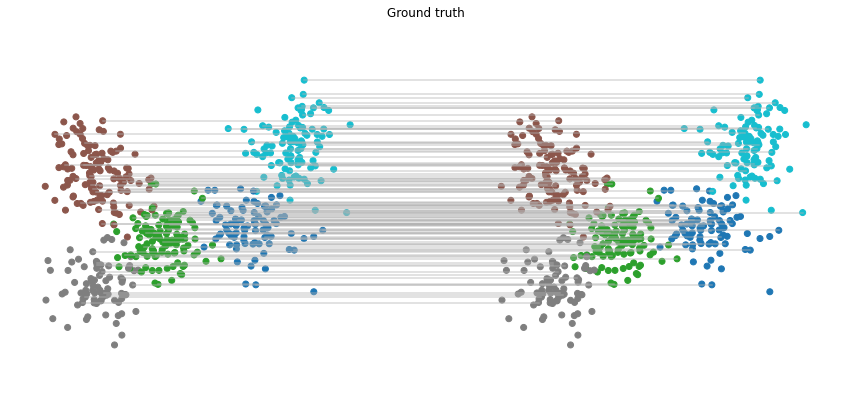

In [18]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [19]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=20, verbose=True, maxIter=200,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)

Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #21,F1=35522.495585109515,F2=0.0,F3=0.0,F4=0.0, 
Iteration #41,F1=35487.85377394956,F2=0.0,F3=0.0,F4=0.0, 
Iteration #61,F1=35473.521421559126,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.61385256545,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.61385256545,F2=0.0,F3=0.0,F4=0.0,Terminating at 81 for tol1 (APPB1)


Text(0.5, 1.0, 'Latent space')

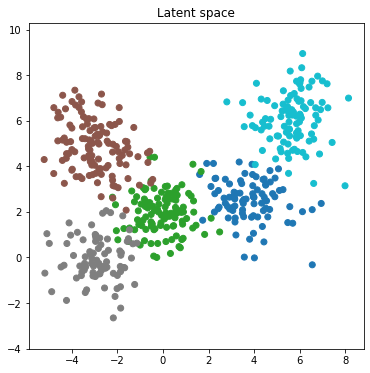

In [20]:
# Visualization of the data
plt.figure(None, (6,6))
plt.scatter(Y[:, 0], Y[:, 1], c=labels, cmap="tab10", label="clusters")
#plt.legend()
plt.axis("equal")
plt.title("Latent space")

Text(0.5, 1.0, 'Solution')

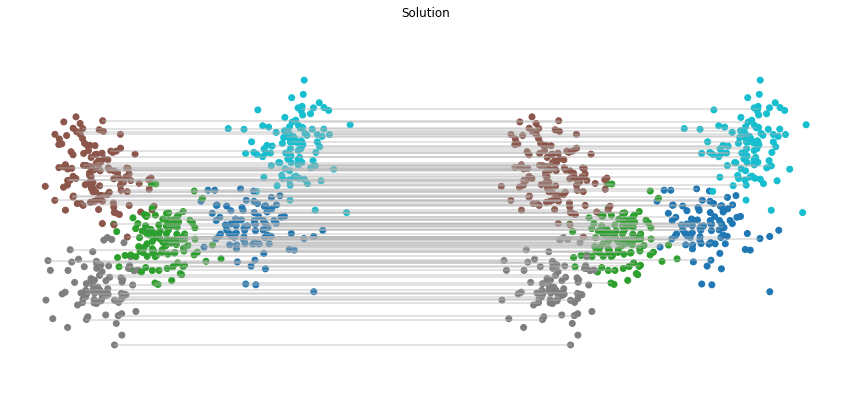

In [22]:
plotP(rng1, Ya,  Yb, A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution")

In [23]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.294, avg_dist_input_I=5.294, avg_dist_groundtruth=0.000, avg_dist_solution=0.000

fract_exact_matches=1.0

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=1.0

latent_score_input=0.054, latent_score_input_I=0.054, latent_score_groundtruth=1.0, latent_score_solution=1.0

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=1.000



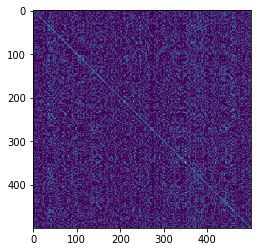

In [24]:

plt.imshow(A)


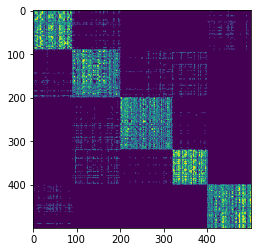

In [25]:

plt.imshow(B)

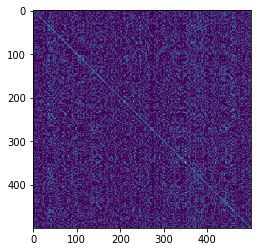

In [26]:

plt.imshow(P0@B@P0.T)

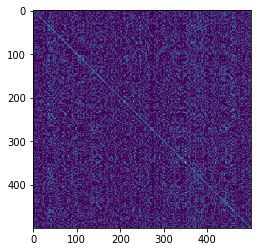

In [27]:
plt.imshow(P_group@B@P_group.T)

In [28]:

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 1 - Identical Latent space, only adjaciency used computed on latent space,  no RNAseq or ATACseq
    

    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = P0 @ Yb
    labels_a = P0 @ labels_b

    A = compute_adjaciency_matrix(Ya, n_neighbors=50)
    B = compute_adjaciency_matrix(Yb, n_neighbors=50)

    # Null matrices
    D = np.zeros((npeaks, ngenes), dtype=int) 
    Xa = np.zeros((ncells, ngenes), dtype=int) 
    Xb = np.zeros((ncells, npeaks), dtype=int) 
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=20, verbose=True, maxIter=500,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")

outF = open("Result_SimData.txt", "w")
outF.write("Simulation1 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #21,F1=35522.495585109515,F2=0.0,F3=0.0,F4=0.0, 
Iteration #41,F1=35487.85377394956,F2=0.0,F3=0.0,F4=0.0, 
Iteration #61,F1=35473.521421559126,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.61385256545,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.61385256545,F2=0.0,F3=0.0,F4=0.0,Terminating at 81 for tol1 (APPB1)
Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #21,F1=35522.4955851095,F2=0.0,F3=0.0,F4=0.0, 
Iteration #41,F1=35487.853773949566,F2=0.0,F3=0.0,F4=0.0, 
Iteration #61,F1=35473.521421559126,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.613852564034,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.613852564034,F2=0.0,F3=0.0,F4=0.0,Terminating at 81 for tol1 (APPB1)
Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #21,F1=35522.4955851095,F2=0.0,F3=0.0,F4=0.0, 
Iteration #41,F1=35487.853773949566,F2=0.0,F3=0.0,F4=0.0, 
Iteration #61,F1=35473.52142155913,F2=0.0,F3=0.0,F4=0.0, 
I

# Simulation 2

In [29]:
# Simulation 2 - Latent space with tiny noise, only adjaciency used and computed on latent space, no RNAseq or ATACseq

# Note the exact solution does not exist

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=10)
labels_a = P0 @ labels_b

A = compute_adjaciency_matrix(Ya, n_neighbors=50)
B = compute_adjaciency_matrix(Yb, n_neighbors=50)

# Null matrices
D = np.zeros((npeaks, ngenes), dtype=int) 
Xa = np.zeros((ncells, ngenes), dtype=int) 
Xb = np.zeros((ncells, npeaks), dtype=int) 

Text(0.5, 1.0, 'Ground truth')

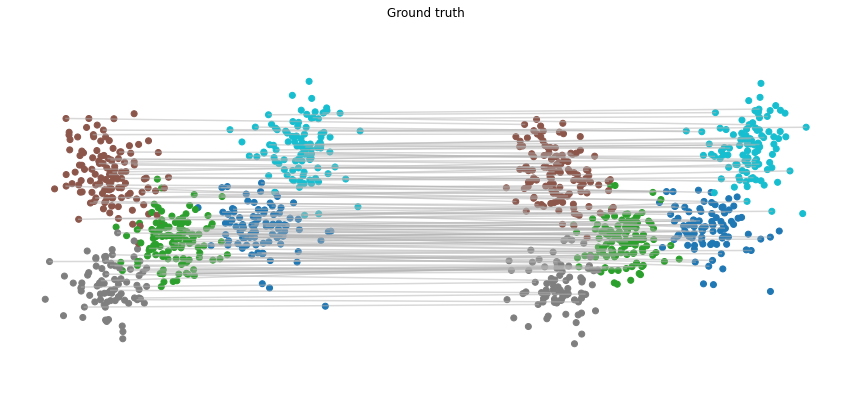

In [30]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [31]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=20, verbose=True, maxIter=500,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)

Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #21,F1=35522.95365896021,F2=0.0,F3=0.0,F4=0.0, 
Iteration #41,F1=35487.10695009742,F2=0.0,F3=0.0,F4=0.0, 
Iteration #61,F1=35473.67287136053,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.73982068645,F2=0.0,F3=0.0,F4=0.0, 
Iteration #101,F1=35462.54376310388,F2=0.0,F3=0.0,F4=0.0, 
Iteration #121,F1=35459.70704900872,F2=0.0,F3=0.0,F4=0.0, 
Iteration #141,F1=35457.63448684301,F2=0.0,F3=0.0,F4=0.0, 
Iteration #161,F1=35456.04153262502,F2=0.0,F3=0.0,F4=0.0, 
Iteration #181,F1=35454.78147284358,F2=0.0,F3=0.0,F4=0.0, 
Iteration #201,F1=35453.755673015316,F2=0.0,F3=0.0,F4=0.0, 
Iteration #221,F1=35452.90066189071,F2=0.0,F3=0.0,F4=0.0, 
Iteration #241,F1=35452.17666311617,F2=0.0,F3=0.0,F4=0.0, 
Iteration #261,F1=35451.55441674569,F2=0.0,F3=0.0,F4=0.0, 
Iteration #281,F1=35451.01172766207,F2=0.0,F3=0.0,F4=0.0, 
Iteration #301,F1=35450.532515035375,F2=0.0,F3=0.0,F4=0.0, 
Iteration #321,F1=35450.10939812054,F2=0.0,F3=0.0,F4=0.0, 


Text(0.5, 1.0, 'Solution')

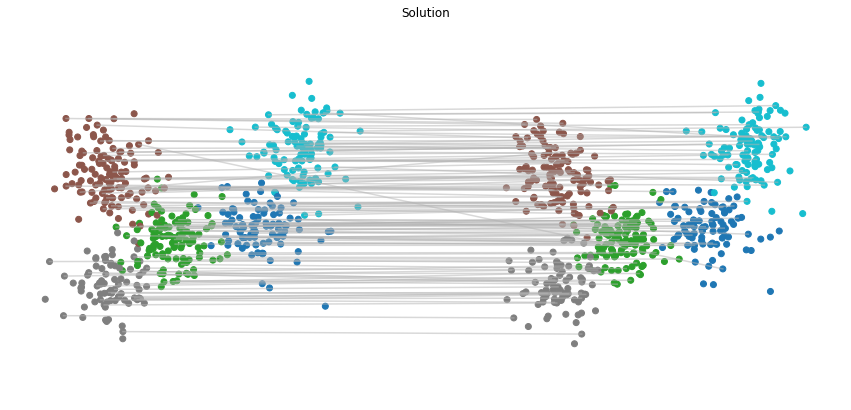

In [32]:
plotP(rng1, Ya,  Yb, A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution")

In [33]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.287, avg_dist_input_I=5.287, avg_dist_groundtruth=0.361, avg_dist_solution=0.477

fract_exact_matches=0.19

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.932

latent_score_input=0.054, latent_score_input_I=0.054, latent_score_groundtruth=0.98, latent_score_solution=0.936

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.870



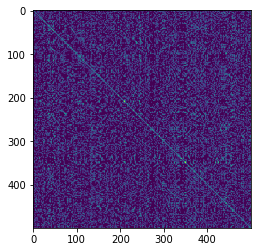

In [34]:
plt.imshow(A)

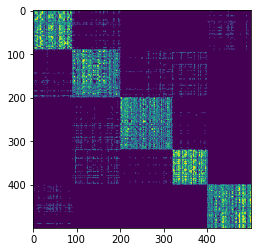

In [35]:
plt.imshow(B)

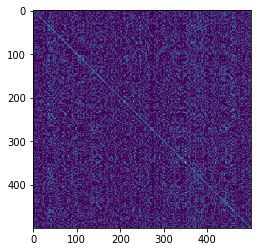

In [36]:
plt.imshow(P0@B@P0.T)

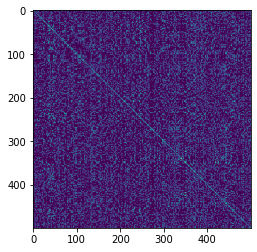

In [37]:
plt.imshow(P_group@B@P_group.T)

In [38]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 2 - Latent space with tiny noise, only adjaciency used and computed on latent space, no RNAseq or ATACseq

    # Note the exact solution does not exist


    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=10)
    labels_a = P0 @ labels_b

    A = compute_adjaciency_matrix(Ya, n_neighbors=50)
    B = compute_adjaciency_matrix(Yb, n_neighbors=50)

    # Null matrices
    D = np.zeros((npeaks, ngenes), dtype=int) 
    Xa = np.zeros((ncells, ngenes), dtype=int) 
    Xb = np.zeros((ncells, npeaks), dtype=int) 
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=20, verbose=True, maxIter=500,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation2 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #21,F1=35522.95365896021,F2=0.0,F3=0.0,F4=0.0, 
Iteration #41,F1=35487.10695009742,F2=0.0,F3=0.0,F4=0.0, 
Iteration #61,F1=35473.67287136053,F2=0.0,F3=0.0,F4=0.0, 
Iteration #81,F1=35466.73982068645,F2=0.0,F3=0.0,F4=0.0, 
Iteration #101,F1=35462.54376310388,F2=0.0,F3=0.0,F4=0.0, 
Iteration #121,F1=35459.70704900872,F2=0.0,F3=0.0,F4=0.0, 
Iteration #141,F1=35457.63448684301,F2=0.0,F3=0.0,F4=0.0, 
Iteration #161,F1=35456.04153262502,F2=0.0,F3=0.0,F4=0.0, 
Iteration #181,F1=35454.78147284358,F2=0.0,F3=0.0,F4=0.0, 
Iteration #201,F1=35453.755673015316,F2=0.0,F3=0.0,F4=0.0, 
Iteration #221,F1=35452.90066189071,F2=0.0,F3=0.0,F4=0.0, 
Iteration #241,F1=35452.17666311617,F2=0.0,F3=0.0,F4=0.0, 
Iteration #261,F1=35451.55441674569,F2=0.0,F3=0.0,F4=0.0, 
Iteration #281,F1=35451.01172766207,F2=0.0,F3=0.0,F4=0.0, 
Iteration #301,F1=35450.532515035375,F2=0.0,F3=0.0,F4=0.0, 
Iteration #321,F1=35450.10939812054,F2=0.0,F3=0.0,F4=0.0, 


# Simulation 3

In [39]:
# Simulation 3 - Latent space with noise(increasing the noise ratio), only adjaciency used and computed on latent space, no RNAseq or ATACseq

# Note the exact solution does not exist

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

A = compute_adjaciency_matrix(Ya, n_neighbors=50)
B = compute_adjaciency_matrix(Yb, n_neighbors=50)

# Null matrices
D = np.zeros((npeaks, ngenes), dtype=int) 
Xa = np.zeros((ncells, ngenes), dtype=int) 
Xb = np.zeros((ncells, npeaks), dtype=int) 

Text(0.5, 1.0, 'Ground truth')

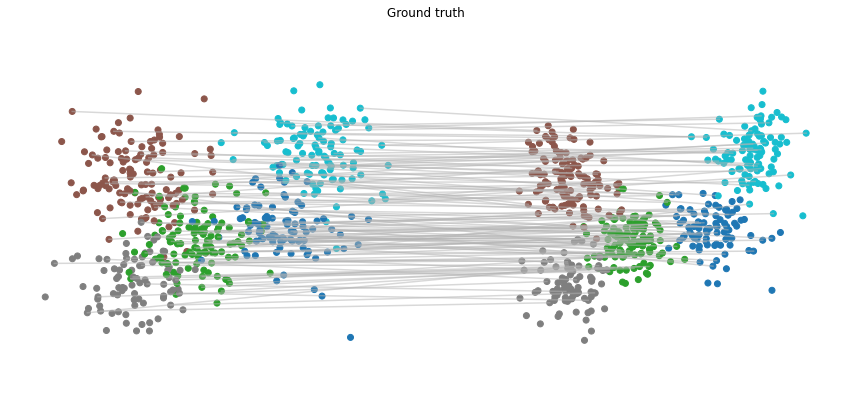

In [40]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [41]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)

Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #51,F1=35530.482408104515,F2=0.0,F3=0.0,F4=0.0, 
Iteration #101,F1=35513.82277321718,F2=0.0,F3=0.0,F4=0.0, 
Iteration #151,F1=35508.82214920083,F2=0.0,F3=0.0,F4=0.0, 
Iteration #201,F1=35506.500156886075,F2=0.0,F3=0.0,F4=0.0, 
Iteration #251,F1=35505.12101215149,F2=0.0,F3=0.0,F4=0.0, 
Iteration #301,F1=35504.21388326882,F2=0.0,F3=0.0,F4=0.0, 
Iteration #351,F1=35503.58821824599,F2=0.0,F3=0.0,F4=0.0, 
Iteration #401,F1=35503.13905980959,F2=0.0,F3=0.0,F4=0.0, 
Iteration #451,F1=35502.801860544234,F2=0.0,F3=0.0,F4=0.0, 
Iteration #501,F1=35502.53876946566,F2=0.0,F3=0.0,F4=0.0, 
Iteration #551,F1=35502.32981589558,F2=0.0,F3=0.0,F4=0.0, 
Iteration #601,F1=35502.15832993761,F2=0.0,F3=0.0,F4=0.0, 
Iteration #651,F1=35502.01983684223,F2=0.0,F3=0.0,F4=0.0, 
Iteration #701,F1=35501.905085844766,F2=0.0,F3=0.0,F4=0.0, 
Iteration #751,F1=35501.80872320373,F2=0.0,F3=0.0,F4=0.0, 
Iteration #801,F1=35501.72654664487,F2=0.0,F3=0.0,F4=0

Text(0.5, 1.0, 'Solution')

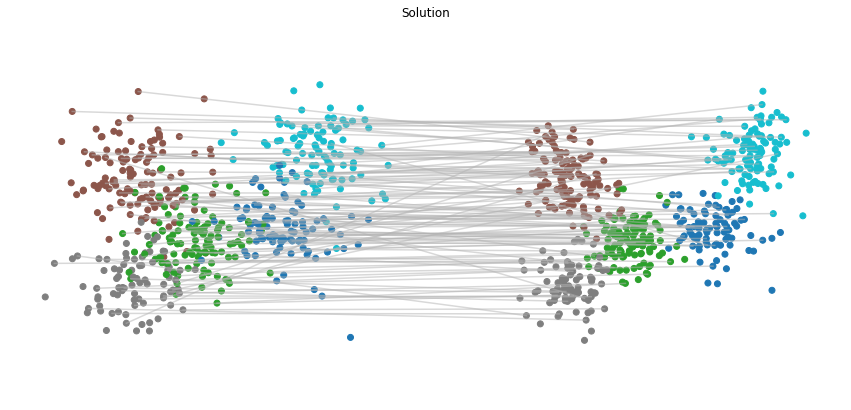

In [42]:
plotP(rng1, Ya,  Yb, A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution")

In [43]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)


avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.564

fract_exact_matches=0.022

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.748

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.588

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.302



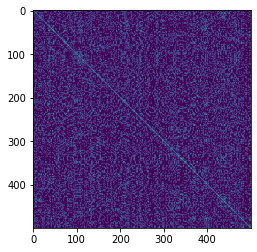

In [44]:
plt.imshow(A)

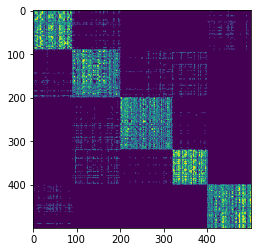

In [45]:
plt.imshow(B)

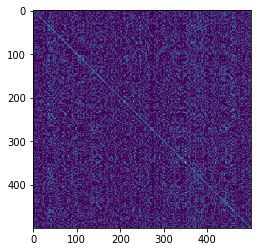

In [46]:
plt.imshow(P0@B@P0.T)

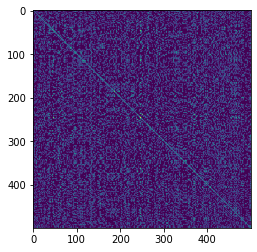

In [47]:
plt.imshow(P_group@B@P_group.T)

In [48]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 3 - Latent space with noise(increasing the noise ratio), only adjaciency used and computed on latent space, no RNAseq or ATACseq

    # Note the exact solution does not exist


    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    A = compute_adjaciency_matrix(Ya, n_neighbors=50)
    B = compute_adjaciency_matrix(Yb, n_neighbors=50)

    # Null matrices
    D = np.zeros((npeaks, ngenes), dtype=int) 
    Xa = np.zeros((ncells, ngenes), dtype=int) 
    Xb = np.zeros((ncells, npeaks), dtype=int) 
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation3 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=36044.190216777155,F2=0.0,F3=0.0,F4=0.0, 
Iteration #51,F1=35530.482408104515,F2=0.0,F3=0.0,F4=0.0, 
Iteration #101,F1=35513.82277321718,F2=0.0,F3=0.0,F4=0.0, 
Iteration #151,F1=35508.82214920083,F2=0.0,F3=0.0,F4=0.0, 
Iteration #201,F1=35506.500156886075,F2=0.0,F3=0.0,F4=0.0, 
Iteration #251,F1=35505.12101215149,F2=0.0,F3=0.0,F4=0.0, 
Iteration #301,F1=35504.21388326882,F2=0.0,F3=0.0,F4=0.0, 
Iteration #351,F1=35503.58821824599,F2=0.0,F3=0.0,F4=0.0, 
Iteration #401,F1=35503.13905980959,F2=0.0,F3=0.0,F4=0.0, 
Iteration #451,F1=35502.801860544234,F2=0.0,F3=0.0,F4=0.0, 
Iteration #501,F1=35502.53876946566,F2=0.0,F3=0.0,F4=0.0, 
Iteration #551,F1=35502.32981589558,F2=0.0,F3=0.0,F4=0.0, 
Iteration #601,F1=35502.15832993761,F2=0.0,F3=0.0,F4=0.0, 
Iteration #651,F1=35502.01983684223,F2=0.0,F3=0.0,F4=0.0, 
Iteration #701,F1=35501.905085844766,F2=0.0,F3=0.0,F4=0.0, 
Iteration #751,F1=35501.80872320373,F2=0.0,F3=0.0,F4=0.0, 
Iteration #801,F1=35501.72654664487,F2=0.0,F3=0.0,F4=0

# Simulation 4

In [49]:
# Simulation 4 - Latent space with noise, only adjaciency used and computed on latent space, no RNAseq or ATACseq
# K Affect
# Note the exact solution does not exist

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

A = compute_adjaciency_matrix(Ya, n_neighbors=100)
B = compute_adjaciency_matrix(Yb, n_neighbors=100)

# Null matrices
D = np.zeros((npeaks, ngenes), dtype=int) 
Xa = np.zeros((ncells, ngenes), dtype=int) 
Xb = np.zeros((ncells, npeaks), dtype=int) 

Text(0.5, 1.0, 'Ground truth')

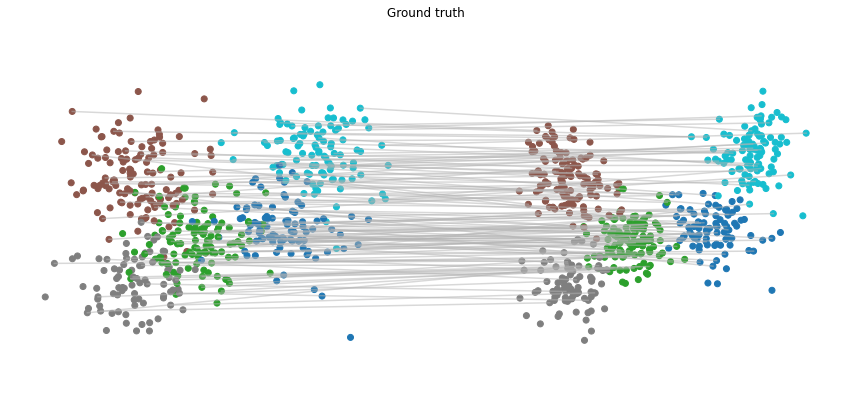

In [50]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [51]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)

Iteration #1,F1=71315.61032643527,F2=0.0,F3=0.0,F4=0.0, 
Iteration #51,F1=70879.24786938565,F2=0.0,F3=0.0,F4=0.0, 
Iteration #101,F1=70853.8141636473,F2=0.0,F3=0.0,F4=0.0, 
Iteration #151,F1=70844.05811014689,F2=0.0,F3=0.0,F4=0.0, 
Iteration #201,F1=70838.53076179663,F2=0.0,F3=0.0,F4=0.0, 
Iteration #251,F1=70834.88289512244,F2=0.0,F3=0.0,F4=0.0, 
Iteration #301,F1=70832.27026930546,F2=0.0,F3=0.0,F4=0.0, 
Iteration #351,F1=70830.28220051409,F2=0.0,F3=0.0,F4=0.0, 
Iteration #401,F1=70828.73217159805,F2=0.0,F3=0.0,F4=0.0, 
Iteration #451,F1=70827.4939231468,F2=0.0,F3=0.0,F4=0.0, 
Iteration #501,F1=70826.48636456091,F2=0.0,F3=0.0,F4=0.0, 
Iteration #551,F1=70825.64642910191,F2=0.0,F3=0.0,F4=0.0, 
Iteration #601,F1=70824.93059055906,F2=0.0,F3=0.0,F4=0.0, 
Iteration #651,F1=70824.31609871828,F2=0.0,F3=0.0,F4=0.0, 
Iteration #701,F1=70823.78580224456,F2=0.0,F3=0.0,F4=0.0, 
Iteration #751,F1=70823.32284266216,F2=0.0,F3=0.0,F4=0.0, 
Iteration #801,F1=70822.91579739584,F2=0.0,F3=0.0,F4=0.0, 
It

Text(0.5, 1.0, 'Solution')

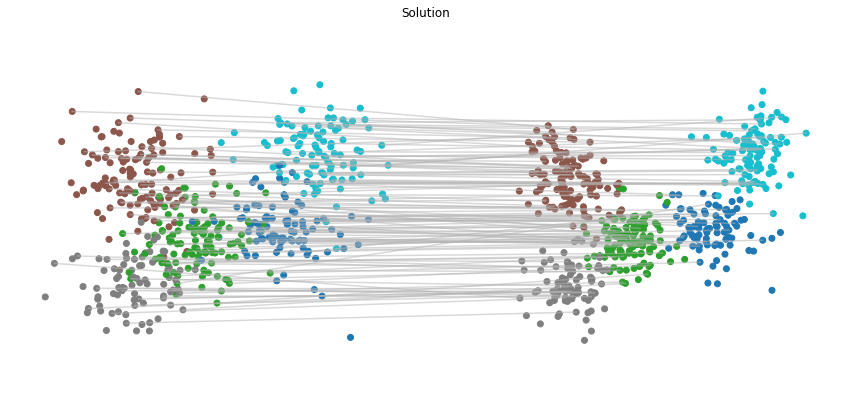

In [52]:
plotP(rng1, Ya,  Yb, A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution")

In [53]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=0.843

fract_exact_matches=0.028

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.808

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.872

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.400



In [54]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 4 - Latent space with noise, only adjaciency used and computed on latent space, no RNAseq or ATACseq
    # K Affect
    # Note the exact solution does not exist

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    A = compute_adjaciency_matrix(Ya, n_neighbors=100)
    B = compute_adjaciency_matrix(Yb, n_neighbors=100)

    # Null matrices
    D = np.zeros((npeaks, ngenes), dtype=int) 
    Xa = np.zeros((ncells, ngenes), dtype=int) 
    Xb = np.zeros((ncells, npeaks), dtype=int) 
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=0, c3=0, c4=0,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation4 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=71315.61032643527,F2=0.0,F3=0.0,F4=0.0, 
Iteration #51,F1=70879.24786938565,F2=0.0,F3=0.0,F4=0.0, 
Iteration #101,F1=70853.8141636473,F2=0.0,F3=0.0,F4=0.0, 
Iteration #151,F1=70844.05811014689,F2=0.0,F3=0.0,F4=0.0, 
Iteration #201,F1=70838.53076179663,F2=0.0,F3=0.0,F4=0.0, 
Iteration #251,F1=70834.88289512244,F2=0.0,F3=0.0,F4=0.0, 
Iteration #301,F1=70832.27026930546,F2=0.0,F3=0.0,F4=0.0, 
Iteration #351,F1=70830.28220051409,F2=0.0,F3=0.0,F4=0.0, 
Iteration #401,F1=70828.73217159805,F2=0.0,F3=0.0,F4=0.0, 
Iteration #451,F1=70827.4939231468,F2=0.0,F3=0.0,F4=0.0, 
Iteration #501,F1=70826.48636456091,F2=0.0,F3=0.0,F4=0.0, 
Iteration #551,F1=70825.64642910191,F2=0.0,F3=0.0,F4=0.0, 
Iteration #601,F1=70824.93059055906,F2=0.0,F3=0.0,F4=0.0, 
Iteration #651,F1=70824.31609871828,F2=0.0,F3=0.0,F4=0.0, 
Iteration #701,F1=70823.78580224456,F2=0.0,F3=0.0,F4=0.0, 
Iteration #751,F1=70823.32284266216,F2=0.0,F3=0.0,F4=0.0, 
Iteration #801,F1=70822.91579739584,F2=0.0,F3=0.0,F4=0.0, 
It

# Simulation 5

In [57]:
# Simulation 5 - Adjaciency computed on latent space but helped by RNAseq and ATACseq
# Note: note the RNA and ATAC matrix are NOT realistic
# Note: no noise is added at the RNAseq and ATACseq level, so their matching all the full info on P0
# Note: No regularization is used

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)

Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

A = compute_adjaciency_matrix(Ya, n_neighbors=100)
B = compute_adjaciency_matrix(Yb, n_neighbors=100)

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
Xa = P0 @ Xb @ D


Text(0.5, 1.0, 'Ground truth')

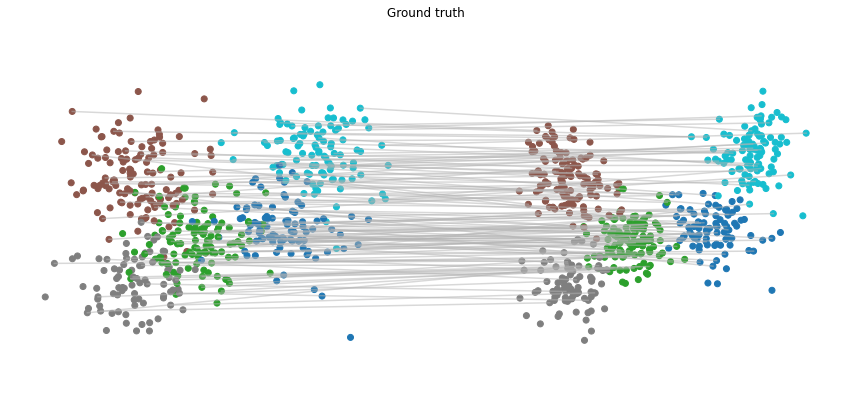

In [58]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [59]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=80, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)

Iteration #1,F1=71524.86642037034,F2=21168.100222303747,F3=0.0,F4=-0.8074763498073283, 
Iteration #81,F1=71840.14378752484,F2=1216.7745049754765,F3=0.0,F4=-22.23189736931792, 
Iteration #161,F1=71724.37650067204,F2=875.5442738977883,F3=0.0,F4=-20.281295317663623, 
Iteration #241,F1=71681.28855132201,F2=726.7853684951549,F3=0.0,F4=-12.903429713738817, 
Iteration #321,F1=71655.07108255483,F2=643.4347440731008,F3=0.0,F4=-2.858164903860483, 
Iteration #401,F1=71636.25031387735,F2=589.184242686818,F3=0.0,F4=8.706393129308625, 
Iteration #481,F1=71621.92235850853,F2=550.4123850938403,F3=0.0,F4=21.253428389223778, 
Iteration #561,F1=71610.41753293217,F2=521.2222456469099,F3=0.0,F4=34.506291009027045, 
Iteration #641,F1=71603.466410347,F2=505.4304498733271,F3=0.0,F4=37.6307883264638, 
Iteration #721,F1=71598.31623292294,F2=494.7640573097292,F3=0.0,F4=37.630788327120676, 
Iteration #801,F1=71594.14545069741,F2=485.8864465480463,F3=0.0,F4=37.63078832737426, 
Iteration #881,F1=71590.66591700555,F

Text(0.5, 1.0, 'Solution')

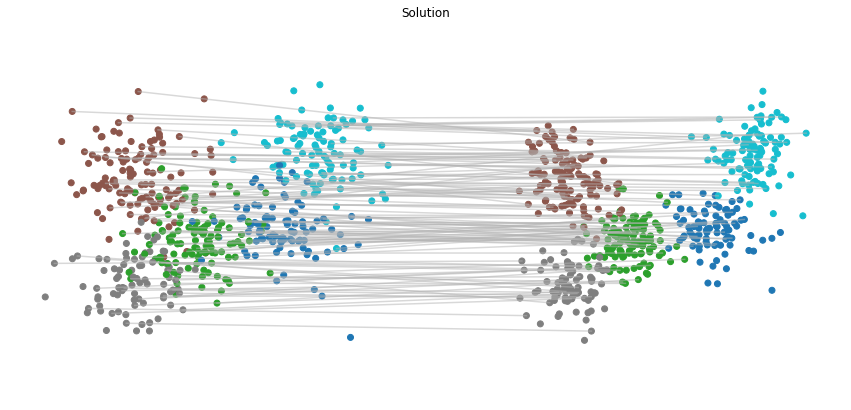

In [61]:
plotP(rng1, Ya,  Yb, A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution")

In [62]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.122

fract_exact_matches=0.268

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.89

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.582

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.866



In [ ]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 5 - Adjaciency computed on latent space but helped by RNAseq and ATACseq
    # Note: note the RNA and ATAC matrix are NOT realistic
    # Note: no noise is added at the RNAseq and ATACseq level, so their matching all the full info on P0
    # Note: No regularization is used

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    A = compute_adjaciency_matrix(Ya, n_neighbors=100)
    B = compute_adjaciency_matrix(Yb, n_neighbors=100)

    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    Xa = P0 @ Xb @ D


    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=80, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation5 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=71524.86642037034,F2=21168.100222303747,F3=0.0,F4=-0.8074763498073283, 
Iteration #81,F1=71840.14378752484,F2=1216.7745049754765,F3=0.0,F4=-22.23189736931792, 
Iteration #161,F1=71724.37650067204,F2=875.5442738977883,F3=0.0,F4=-20.281295317663623, 
Iteration #241,F1=71681.28855132201,F2=726.7853684951549,F3=0.0,F4=-12.903429713738817, 
Iteration #321,F1=71655.07108255483,F2=643.4347440731008,F3=0.0,F4=-2.858164903860483, 
Iteration #401,F1=71636.25031387735,F2=589.184242686818,F3=0.0,F4=8.706393129308625, 
Iteration #481,F1=71621.92235850853,F2=550.4123850938403,F3=0.0,F4=21.253428389223778, 
Iteration #561,F1=71610.41753293217,F2=521.2222456469099,F3=0.0,F4=34.506291009027045, 
Iteration #641,F1=71603.466410347,F2=505.4304498733271,F3=0.0,F4=37.6307883264638, 
Iteration #721,F1=71598.31623292294,F2=494.7640573097292,F3=0.0,F4=37.630788327120676, 
Iteration #801,F1=71594.14545069741,F2=485.8864465480463,F3=0.0,F4=37.63078832737426, 
Iteration #881,F1=71590.66591700555,F

# Simulation 6 

In [9]:
# Simulation 6 - Adjaciency computed on latent space but helped by NOISY RNAseq and ATACseq
# Note: note the RNA and ATAC matrix are NOT realistic but it is noisy
# Note: No regularization is used

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

A = compute_adjaciency_matrix(Ya, n_neighbors=100)
B = compute_adjaciency_matrix(Yb, n_neighbors=100)

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
Xa = P0 @ Xb @ D

Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

Text(0.5, 1.0, 'Ground truth')

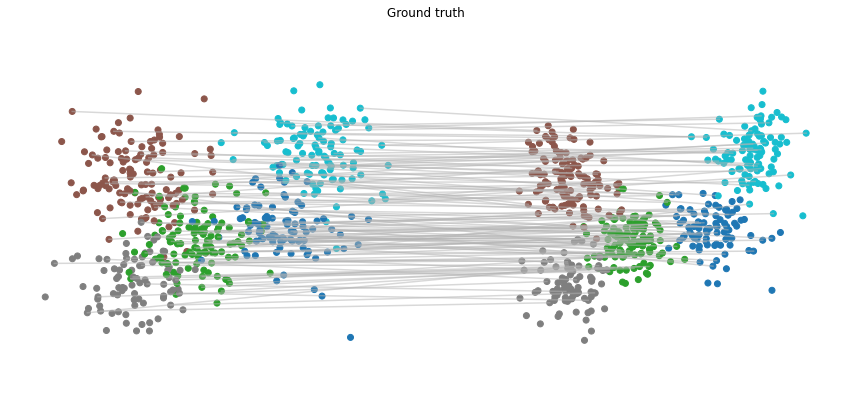

In [10]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [11]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)

Iteration #1,F1=71417.71639062025,F2=21062.22267783185,F3=0.0,F4=-0.4093183796068308, 
Iteration #51,F1=71809.0020266255,F2=2131.8049151593527,F3=0.0,F4=-14.562741558671139, 
Iteration #101,F1=71671.8864756987,F2=1690.9563634002836,F3=0.0,F4=-16.20349595930855, 
Iteration #151,F1=71614.68579425708,F2=1494.9785126950437,F3=0.0,F4=-14.064503053752414, 
Iteration #201,F1=71586.37283222967,F2=1376.5500887202459,F3=0.0,F4=-9.929437984615001, 
Iteration #251,F1=71569.29333048926,F2=1295.465788216075,F3=0.0,F4=-4.547064477447881, 
Iteration #301,F1=71557.08576682289,F2=1236.5500959923154,F3=0.0,F4=1.6963699458772241, 
Iteration #351,F1=71547.37340585659,F2=1192.0236821162314,F3=0.0,F4=8.559459835531525, 
Iteration #401,F1=71539.55265578648,F2=1156.553798884879,F3=0.0,F4=15.89087041506164, 
Iteration #451,F1=71532.89523393552,F2=1127.6232619540056,F3=0.0,F4=23.589270306800127, 
Iteration #501,F1=71527.12588227037,F2=1103.5007524083112,F3=0.0,F4=31.585898510473783, 
Iteration #551,F1=71522.0852

Text(0.5, 1.0, 'Solution')

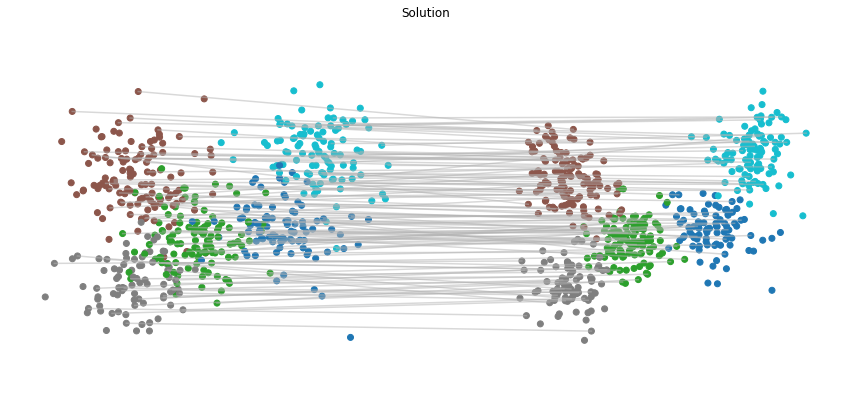

In [12]:
plotP(rng1, Ya,  Yb, A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution")

In [13]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.093

fract_exact_matches=0.2

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.894

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.602

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.864



In [ ]:
#np.random.seed(19900715)
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 6 - Adjaciency computed on latent space but helped by NOISY RNAseq and ATACseq
    # Note: note the RNA and ATAC matrix are NOT realistic but it is noisy
    # Note: No regularization is used

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    A = compute_adjaciency_matrix(Ya, n_neighbors=100)
    B = compute_adjaciency_matrix(Yb, n_neighbors=100)

    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    Xa = P0 @ Xb @ D

    Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
    Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=9e-17, tolbar=1e-5,  tol2=9e-16)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation6 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=71417.71639062025,F2=21062.22267783185,F3=0.0,F4=-0.4093183796068308, 
Iteration #51,F1=71809.0020266255,F2=2131.8049151593527,F3=0.0,F4=-14.562741558671139, 
Iteration #101,F1=71671.8864756987,F2=1690.9563634002836,F3=0.0,F4=-16.20349595930855, 
Iteration #151,F1=71614.68579425708,F2=1494.9785126950437,F3=0.0,F4=-14.064503053752414, 
Iteration #201,F1=71586.37283222967,F2=1376.5500887202459,F3=0.0,F4=-9.929437984615001, 
Iteration #251,F1=71569.29333048926,F2=1295.465788216075,F3=0.0,F4=-4.547064477447881, 
Iteration #301,F1=71557.08576682289,F2=1236.5500959923154,F3=0.0,F4=1.6963699458772241, 
Iteration #351,F1=71547.37340585659,F2=1192.0236821162314,F3=0.0,F4=8.559459835531525, 
Iteration #401,F1=71539.55265578648,F2=1156.553798884879,F3=0.0,F4=15.89087041506164, 
Iteration #451,F1=71532.89523393552,F2=1127.6232619540056,F3=0.0,F4=23.589270306800127, 
Iteration #501,F1=71527.12588227037,F2=1103.5007524083112,F3=0.0,F4=31.585898510473783, 
Iteration #551,F1=71522.0852

# Simulation 7

In [9]:
# Simulation 7 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
# Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
# Note: No regularization is used

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
Xa = P0 @ Xb @ D

Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

pca_Xa = PCA(4).fit_transform(Xa)
pca_Xb = PCA(4).fit_transform(Xb)
A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)

Text(0.5, 1.0, 'Ground truth')

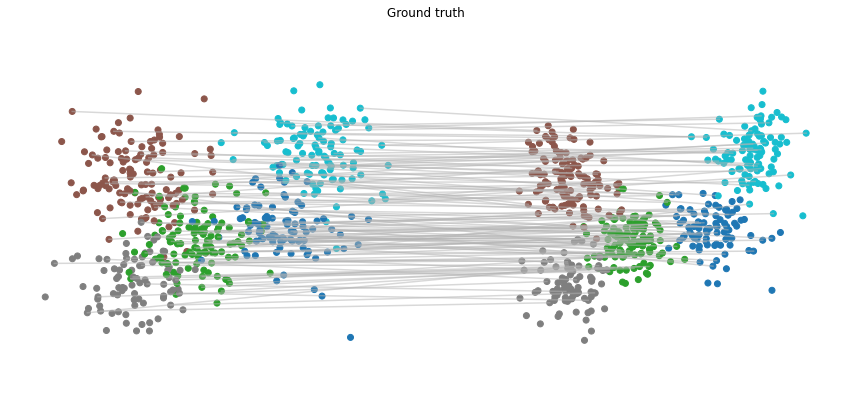

In [10]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [11]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)

Iteration #1,F1=71389.85404664149,F2=20738.61618555762,F3=0.0,F4=-0.41902041313714194, 
Iteration #51,F1=71459.40915908775,F2=1862.2581451256078,F3=0.0,F4=-13.97320982185173, 
Iteration #101,F1=71292.29481149398,F2=1387.5882087540615,F3=0.0,F4=-14.187225139641095, 
Iteration #151,F1=71214.95783452732,F2=1185.4412334939905,F3=0.0,F4=-10.354107990434587, 
Iteration #201,F1=71170.01899108912,F2=1064.9794946149532,F3=0.0,F4=-4.435909341902607, 
Iteration #251,F1=71138.33892270489,F2=984.7746169408139,F3=0.0,F4=2.737714113389158, 
Iteration #301,F1=71113.55285527781,F2=927.8592528123013,F3=0.0,F4=10.733281680180546, 
Iteration #351,F1=71094.24920884262,F2=890.9763517016734,F3=0.0,F4=11.232930011014368, 
Iteration #401,F1=71077.98913949849,F2=862.4486225907135,F3=0.0,F4=11.23293001107513, 
Iteration #451,F1=71064.2364491277,F2=839.4180059568872,F3=0.0,F4=11.232930011118754, 
Iteration #501,F1=71052.4682299171,F2=820.2419560473706,F3=0.0,F4=11.23293001114284, 
Iteration #551,F1=71042.28346380

Text(0.5, 1.0, 'Solution')

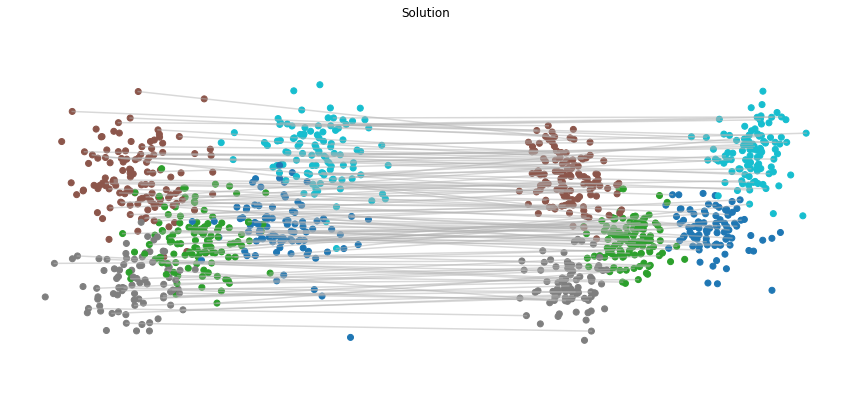

In [12]:
plotP(rng1, Ya,  Yb, A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution")

In [13]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.210

fract_exact_matches=0.642

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.988

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.52

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=1.000



In [ ]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 7 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
    # Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
    # Note: No regularization is used

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    Xa = P0 @ Xb @ D

    Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
    Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

    pca_Xa = PCA(4).fit_transform(Xa)
    pca_Xb = PCA(4).fit_transform(Xb)
    A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
    B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation7 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

# Simulation 8

In [14]:
# Simulation 8 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
# The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
# Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
# Note: Regularization No

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.05)
D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
Xa = P0 @ Xb @ D_changed

Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

pca_Xa = PCA(4).fit_transform(Xa)
pca_Xb = PCA(4).fit_transform(Xb)
A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)

Text(0.5, 1.0, 'Ground truth')

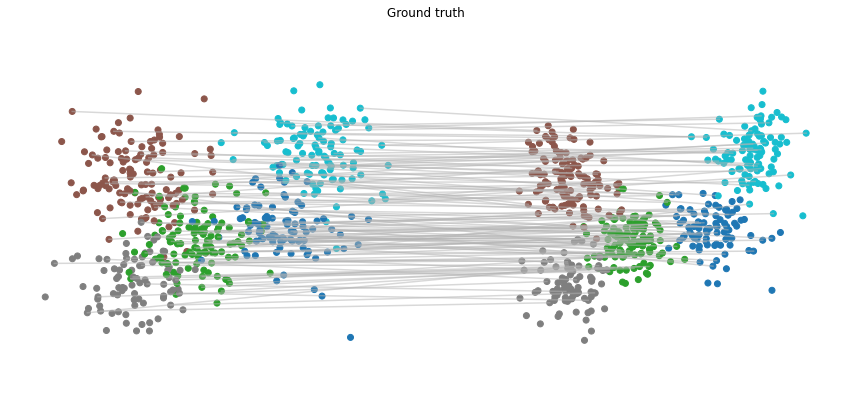

In [15]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [16]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)

Iteration #1,F1=71359.78738932719,F2=29223.489048455514,F3=0.0,F4=0.646939894303779, 
Iteration #51,F1=71379.0593593093,F2=12840.829834562359,F3=0.0,F4=44.12660157057423, 
Iteration #101,F1=71275.36747667269,F2=8695.903669484678,F3=0.0,F4=102.74866637257222, 
Iteration #151,F1=71216.51075905579,F2=6262.773839518636,F3=0.0,F4=180.5763221083022, 
Iteration #201,F1=71167.36268838249,F2=6122.421829479853,F3=0.0,F4=195.08571183393718, 
Iteration #251,F1=71132.67589027468,F2=6074.399026253664,F3=0.0,F4=195.08571183394542, 
Iteration #301,F1=71107.06762282403,F2=6040.884470396405,F3=0.0,F4=195.08571183395156, 
Iteration #351,F1=71086.83212466318,F2=6015.919100597568,F3=0.0,F4=195.08571183396407, 
Iteration #401,F1=71070.25065344063,F2=5996.564517329324,F3=0.0,F4=195.08571183397223, 
Iteration #451,F1=71056.34161916771,F2=5981.102681319772,F3=0.0,F4=195.0857118339779, 
Iteration #501,F1=71044.57264518122,F2=5968.4527007637535,F3=0.0,F4=195.0857118339904, 
Iteration #551,F1=71034.42894595886,F2

Text(0.5, 1.0, 'Solution - PCA')

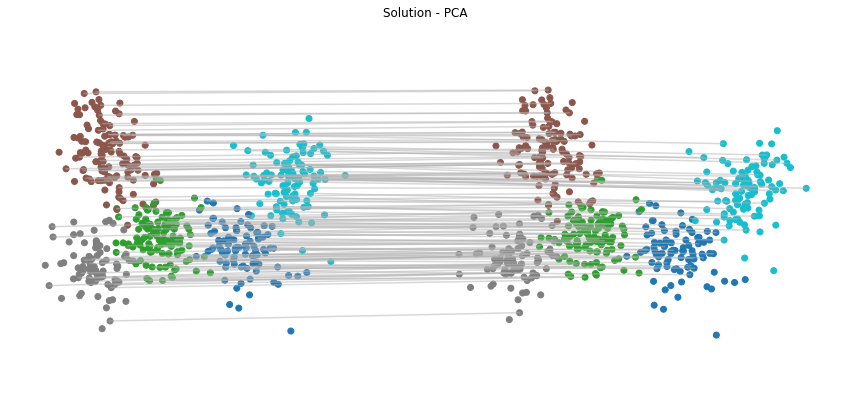

In [17]:
plotP(rng1, pca_Xa[:,:2],  pca_Xb[:,:2], A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution - PCA")

In [18]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.210

fract_exact_matches=0.636

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.984

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.526

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.998



In [ ]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 8 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
    # The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
    # Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
    # Note: Regularization No

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
    D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
    D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.05)
    D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
    Xa = P0 @ Xb @ D_changed

    Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
    Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

    pca_Xa = PCA(4).fit_transform(Xa)
    pca_Xb = PCA(4).fit_transform(Xb)
    A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
    B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation8 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

# Simulation 8'

In [52]:
# Simulation 8' - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
# The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)-More Noisy
# Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
# Note: Regularization No

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.7 )
D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
Xa = P0 @ Xb @ D_changed

Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

pca_Xa = PCA(4).fit_transform(Xa)
pca_Xb = PCA(4).fit_transform(Xb)
A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)

Text(0.5, 1.0, 'Ground truth')

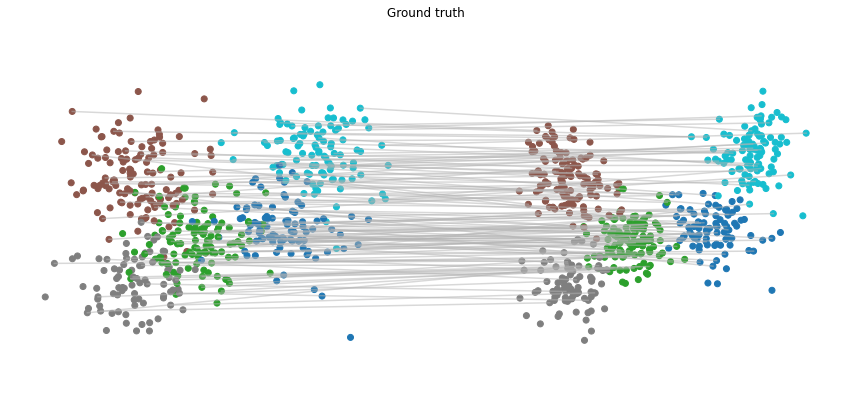

In [53]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [54]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)

Iteration #1,F1=71331.34730803409,F2=29040.93668024031,F3=0.0,F4=2.4069499290071112, 
Iteration #51,F1=71171.24571407896,F2=17640.777302183495,F3=0.0,F4=123.3504995989409, 
Iteration #101,F1=71110.29619810534,F2=11855.59849575421,F3=0.0,F4=245.78351632993594, 
Iteration #151,F1=71081.0919964768,F2=9245.002189629427,F3=0.0,F4=365.4933193237131, 
Iteration #201,F1=71050.9168280293,F2=9210.072185281695,F3=0.0,F4=365.49331932375196, 
Iteration #251,F1=71027.17287573147,F2=9195.71189527697,F3=0.0,F4=365.49331932378914, 
Iteration #301,F1=71008.5739103094,F2=9187.205828943032,F3=0.0,F4=365.49331932382677, 
Iteration #351,F1=70994.46384500999,F2=9181.385327338916,F3=0.0,F4=365.4933193238644, 
Iteration #401,F1=70983.44545223599,F2=9176.978033935371,F3=0.0,F4=365.4933193239033, 
Iteration #451,F1=70974.6491770593,F2=9173.502408276627,F3=0.0,F4=365.4933193239409, 
Iteration #501,F1=70967.4525937905,F2=9170.71744273695,F3=0.0,F4=365.4933193239793, 
Iteration #551,F1=70961.47052478194,F2=9168.403

Text(0.5, 1.0, 'Solution - PCA')

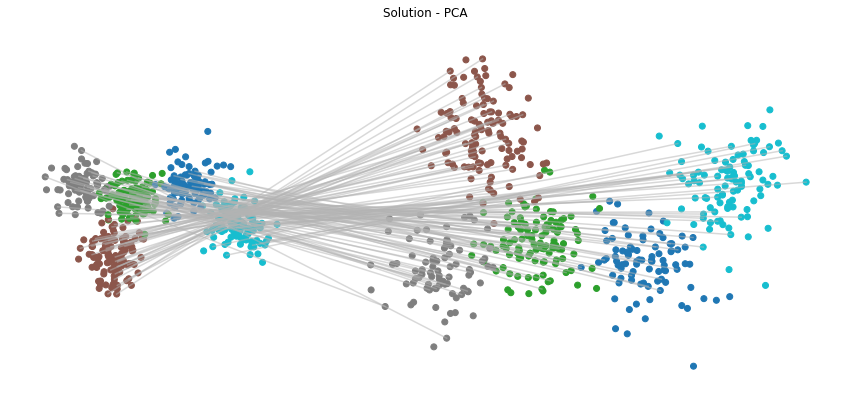

In [55]:
plotP(rng1, pca_Xa[:,:2],  pca_Xb[:,:2], A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution - PCA")

In [56]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.297

fract_exact_matches=0.388

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.956

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.478

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.934



In [83]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 8' - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
    # The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
    # Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
    # Note: Regularization No

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
    D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
    D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.7)
    D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
    Xa = P0 @ Xb @ D_changed

    Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
    Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

    pca_Xa = PCA(4).fit_transform(Xa)
    pca_Xb = PCA(4).fit_transform(Xb)
    A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
    B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=0, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n") 
outF = open("Result_SimData.txt", "a")
outF.write("Simulation8' \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=71331.34730803409,F2=29040.93668024031,F3=0.0,F4=2.4069499290071112, 
Iteration #51,F1=71171.24571407896,F2=17640.777302183495,F3=0.0,F4=123.3504995989409, 
Iteration #101,F1=71110.29619810534,F2=11855.59849575421,F3=0.0,F4=245.78351632993594, 
Iteration #151,F1=71081.0919964768,F2=9245.002189629427,F3=0.0,F4=365.4933193237131, 
Iteration #201,F1=71050.9168280293,F2=9210.072185281695,F3=0.0,F4=365.49331932375196, 
Iteration #251,F1=71027.17287573147,F2=9195.71189527697,F3=0.0,F4=365.49331932378914, 
Iteration #301,F1=71008.5739103094,F2=9187.205828943032,F3=0.0,F4=365.49331932382677, 
Iteration #351,F1=70994.46384500999,F2=9181.385327338916,F3=0.0,F4=365.4933193238644, 
Iteration #401,F1=70983.44545223599,F2=9176.978033935371,F3=0.0,F4=365.4933193239033, 
Iteration #451,F1=70974.6491770593,F2=9173.502408276627,F3=0.0,F4=365.4933193239409, 
Iteration #501,F1=70967.4525937905,F2=9170.71744273695,F3=0.0,F4=365.4933193239793, 
Iteration #551,F1=70961.47052478194,F2=9168.403

# Simulation 9

In [117]:
# Simulation 9 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
# The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
# Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
# Note: Regularization yes

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.05)
D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
Xa = P0 @ Xb @ D_changed

Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

pca_Xa = PCA(4).fit_transform(Xa)
pca_Xb = PCA(4).fit_transform(Xb)
A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)

Text(0.5, 1.0, 'Ground truth')

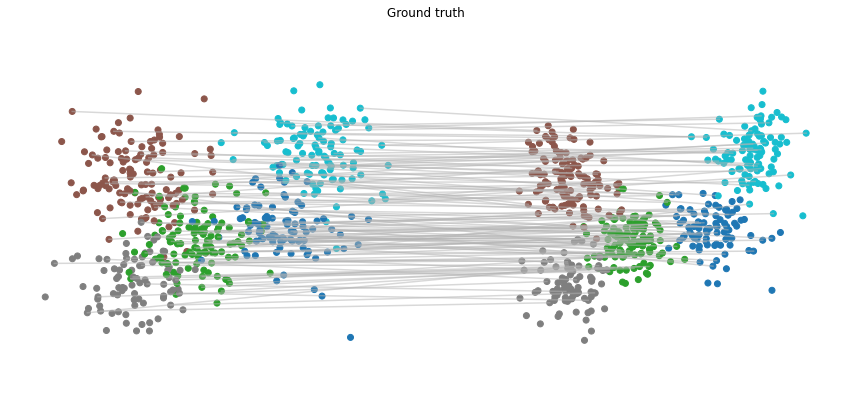

In [118]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [109]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=20, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)

Iteration #1,F1=71359.78738932719,F2=29220.373151663844,F3=19978.876264660605,F4=2.6476000455940882, 
Iteration #51,F1=71382.20858097197,F2=12716.531519476686,F3=19006.587014233413,F4=145.14477564073718, 
Iteration #101,F1=71281.73794365389,F2=8530.135758329587,F3=18154.89508710771,F4=302.1517603126406, 
Iteration #151,F1=71222.81314027336,F2=6121.595170925346,F3=17399.226309647613,F4=492.83966429321754, 
Iteration #201,F1=71172.53137949982,F2=6023.295813170553,F3=17399.226309647613,F4=492.83966429323857, 
Iteration #251,F1=71137.93957931206,F2=5963.741377702607,F3=17399.226309647613,F4=492.83966429326097, 
Iteration #301,F1=71112.64893232065,F2=5922.061388375305,F3=17399.226309647613,F4=492.8396642932835, 
Iteration #351,F1=71092.76713858343,F2=5890.861001282536,F3=17399.226309647613,F4=492.8396642933045, 
Iteration #401,F1=71076.48973344635,F2=5866.646988921955,F3=17399.226309647613,F4=492.83966429332554, 
Iteration #451,F1=71062.80024069952,F2=5847.228836121423,F3=17399.226309647613

Text(0.5, 1.0, 'Solution - PCA')

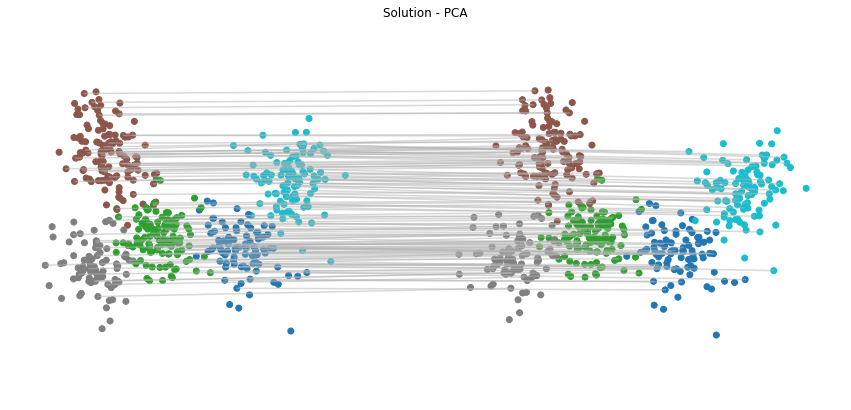

In [110]:
plotP(rng1, pca_Xa[:,:2],  pca_Xb[:,:2], A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution - PCA")

In [111]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.210

fract_exact_matches=0.65

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.984

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.528

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.998



In [32]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 9 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
    # The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
    # Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
    # Note: Regularization yes

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b

    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
    D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
    D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.05)
    D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
    Xa = P0 @ Xb @ D_changed

    Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
    Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

    pca_Xa = PCA(4).fit_transform(Xa)
    pca_Xb = PCA(4).fit_transform(Xb)
    A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
    B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=20, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")   
outF = open("Result_SimData.txt", "a")
outF.write("Simulation9 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=71359.78738932719,F2=29220.373151663844,F3=19978.876264660605,F4=2.6476000455940882, 
Iteration #51,F1=71382.20858097197,F2=12716.531519476686,F3=19006.587014233413,F4=145.14477564073718, 
Iteration #101,F1=71281.73794365389,F2=8530.135758329587,F3=18154.89508710771,F4=302.1517603126406, 
Iteration #151,F1=71222.81314027336,F2=6121.595170925346,F3=17399.226309647613,F4=492.83966429321754, 
Iteration #201,F1=71172.53137949982,F2=6023.295813170553,F3=17399.226309647613,F4=492.83966429323857, 
Iteration #251,F1=71137.93957931206,F2=5963.741377702607,F3=17399.226309647613,F4=492.83966429326097, 
Iteration #301,F1=71112.64893232065,F2=5922.061388375305,F3=17399.226309647613,F4=492.8396642932835, 
Iteration #351,F1=71092.76713858343,F2=5890.861001282536,F3=17399.226309647613,F4=492.8396642933045, 
Iteration #401,F1=71076.48973344635,F2=5866.646988921955,F3=17399.226309647613,F4=492.83966429332554, 
Iteration #451,F1=71062.80024069952,F2=5847.228836121423,F3=17399.226309647613

# Simulation 9'

In [119]:
# Simulation 9' - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
# The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
# Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
# Note: Regularization yes

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.7)
D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
Xa = P0 @ Xb @ D_changed

Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

pca_Xa = PCA(4).fit_transform(Xa)
pca_Xb = PCA(4).fit_transform(Xb)
A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)

Text(0.5, 1.0, 'Ground truth')

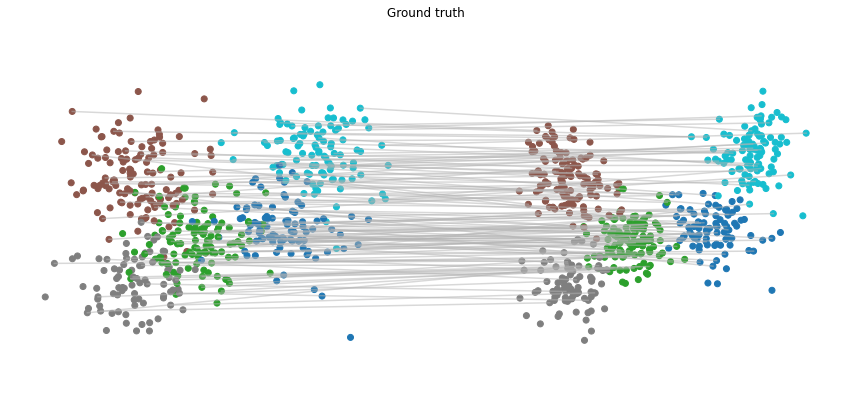

In [120]:
plotP(rng1, Ya,  Yb, A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("Ground truth")

In [114]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=2000, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)

Iteration #1,F1=71331.34730803409,F2=27379.710403624198,F3=1841362.1332217162,F4=206.61750871282953, 
Iteration #51,F1=71178.52979799699,F2=11602.454489357597,F3=45164.51057492202,F4=9727.501538340945, 
Iteration #101,F1=71115.4406068882,F2=11251.1921324006,F3=45165.76697065443,F4=9727.501538340945, 
Iteration #151,F1=71088.56796244328,F2=11072.128227188923,F3=45167.028704059434,F4=9727.501538340945, 
Iteration #201,F1=71063.31312251807,F2=10964.968135026014,F3=45168.29577513704,F4=9727.501538340945, 
Iteration #251,F1=71042.08739766243,F2=10891.2781375555,F3=45169.56818388725,F4=9727.501538340945, 
Iteration #301,F1=71025.06434451438,F2=10837.570424586756,F3=45170.84593031005,F4=9727.501538340945, 
Iteration #351,F1=71010.8783498119,F2=10798.131348436713,F3=45172.129014405444,F4=9727.501538340945, 
Iteration #401,F1=70999.19247012226,F2=10768.518068500836,F3=45173.41743617344,F4=9727.501538340945, 
Iteration #451,F1=70989.48827947305,F2=10745.914309216347,F3=45174.711195614036,F4=9727

Text(0.5, 1.0, 'Solution - PCA')

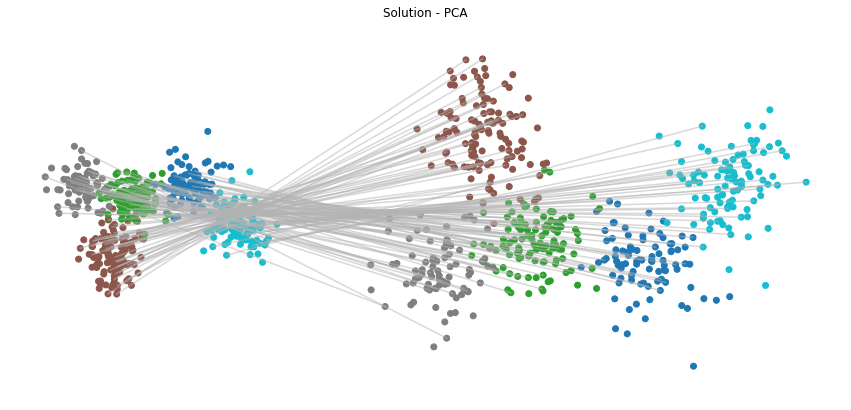

In [115]:
plotP(rng1, pca_Xa[:,:2],  pca_Xb[:,:2], A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution - PCA")

In [116]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=1.213

fract_exact_matches=0.528

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.966

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.506

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.990



In [ ]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 9' - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
    # The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
    # Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
    # Note: Regularization yes

    

    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_r elative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a =                                                                              P0 @ labels_b

    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
    D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
    D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.7)
    D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
    Xa = P0 @ Xb @ D_changed

    Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
    Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

    pca_Xa = PCA(4).fit_transform(Xa)
    pca_Xb = PCA(4).fit_transform(Xb)
    A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
    B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=2000, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")   
outF = open("Result_SimData.txt", "a")
outF.write("Simulation9' \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=71331.34730803409,F2=27379.710403624198,F3=1841362.1332217162,F4=206.61750871282953, 
Iteration #51,F1=71178.52979799699,F2=11602.454489357597,F3=45164.51057492202,F4=9727.501538340945, 
Iteration #101,F1=71115.4406068882,F2=11251.1921324006,F3=45165.76697065443,F4=9727.501538340945, 
Iteration #151,F1=71088.56796244328,F2=11072.128227188923,F3=45167.028704059434,F4=9727.501538340945, 
Iteration #201,F1=71063.31312251807,F2=10964.968135026014,F3=45168.29577513704,F4=9727.501538340945, 
Iteration #251,F1=71042.08739766243,F2=10891.2781375555,F3=45169.56818388725,F4=9727.501538340945, 
Iteration #301,F1=71025.06434451438,F2=10837.570424586756,F3=45170.84593031005,F4=9727.501538340945, 
Iteration #351,F1=71010.8783498119,F2=10798.131348436713,F3=45172.129014405444,F4=9727.501538340945, 
Iteration #401,F1=70999.19247012226,F2=10768.518068500836,F3=45173.41743617344,F4=9727.501538340945, 
Iteration #451,F1=70989.48827947305,F2=10745.914309216347,F3=45174.711195614036,F4=9727

# Simulation 10

In [24]:
# Simulation 10 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
# The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
# Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
# Note: Regularization yes

#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
P0 = make_random_P(rng1, Y.shape[0])

labels_b = labels
Yb = Y

Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
labels_a = P0 @ labels_b

Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
D = make_blockdiag_D(npeaks, ngenes)
D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.05)
D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
Xa = P0 @ Xb @ D_changed

Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

Xa = from_normal_to_poisson2(rng2, Xa, factor=(4, 8))
Xb = from_normal_to_poisson2(rng2, Xb, factor=(1, 2))

pca_Xa = PCA(5).fit_transform(np.log(Xa+1))
pca_Xb = PCA(5).fit_transform(np.log(Xb+1))
A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)

Text(0.5, 1.0, 'PCA')

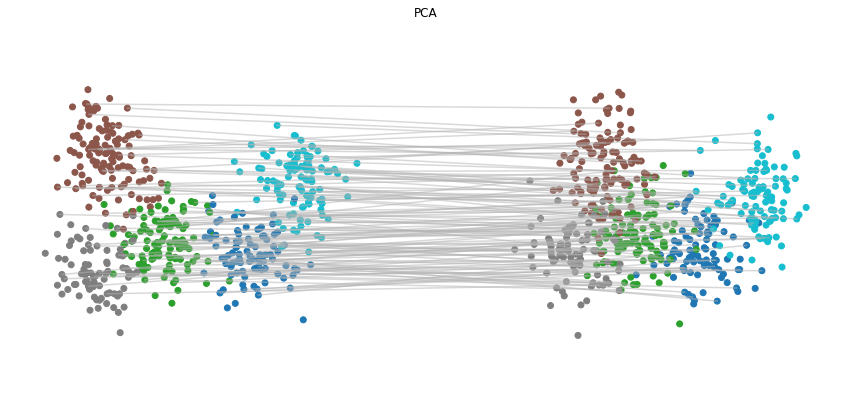

In [27]:
plotP(rng1, pca_Xa[:,:2],  pca_Xb[:,:2], A, B, P0, labels_a, labels_b, show_fraction=0.25)
plt.title("PCA")

In [26]:
Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=20, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)

Iteration #1,F1=72820.35290694828,F2=16318353.401600081,F3=5817.734935507259,F4=33192.59359256189, 
Iteration #51,F1=74638.55557862208,F2=15555520.143121913,F3=5819.351738847205,F4=33192.593592561585, 
Iteration #101,F1=75900.89526721461,F2=15355412.647196343,F3=5820.977509477117,F4=33192.59359256128, 
Iteration #151,F1=76603.10751763284,F2=15266280.14118843,F3=5822.612247396994,F4=33192.59359256098, 
Iteration #201,F1=77070.11135263428,F2=15215790.172635917,F3=5824.255952606833,F4=33192.593592560675, 
Iteration #251,F1=77415.31343238731,F2=15184487.817631442,F3=5825.9086251066365,F4=33192.59359256037, 
Iteration #301,F1=77684.0531068167,F2=15164624.066856243,F3=5827.570264896412,F4=33192.59359256007, 
Iteration #351,F1=77904.65711213992,F2=15152161.79971983,F3=5829.240871976139,F4=33192.59359255976, 
Iteration #401,F1=78091.80357115199,F2=15144883.607991684,F3=5830.920446345836,F4=33192.59359255946, 
Iteration #451,F1=78252.83651375781,F2=15141404.779651156,F3=5832.6089880055,F4=33192

Text(0.5, 1.0, 'Solution - PCA')

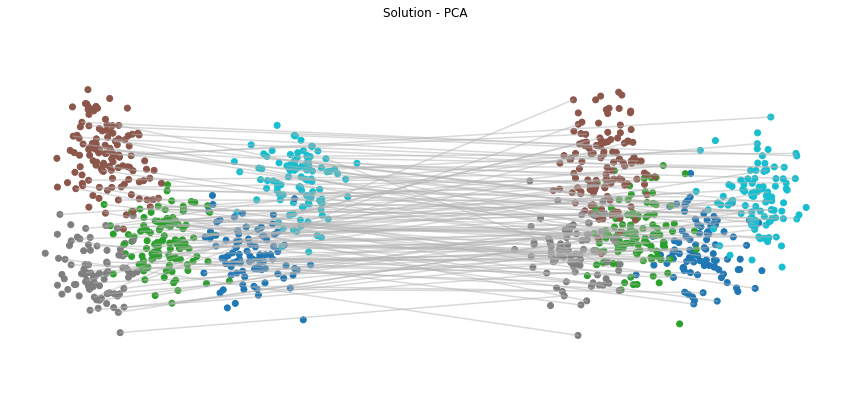

In [30]:
plotP(rng1, pca_Xa[:,:2],  pca_Xb[:,:2], A, B, P_group, labels_a, labels_b, show_fraction=0.25)
plt.title("Solution - PCA")

In [29]:
print_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)

avg_dist_input=5.393, avg_dist_input_I=5.393, avg_dist_groundtruth=1.203, avg_dist_solution=3.756

fract_exact_matches=0.008

label_accuracy_input=0.208, label_accuracy_input_I=0.208, label_accuracy_groundtruth=1.0, label_accuracy=0.442

latent_score_input=0.046, latent_score_input_I=0.046, latent_score_groundtruth=0.522, latent_score_solution=0.102

relaxed_match_accuracy_input=0.054, relaxed_match_accuracy_input_I=0.054,relaxed_match_accuracy_groundtruth=1.000, relaxed_match_accuracy=0.104



In [104]:
#np.random.seed(19900715)
random_seed1=19900715
rng1=np.random.default_rng(random_seed1)
rng2=np.random.default_rng(random_seed1)
avg_dist_input_list = []
avg_dist_input_I_list = []
avg_dist_groundtruth_list = []
avg_dist_solution_list = []
label_accuracy_input_list = []
label_accuracy_input_I_list = []
label_accuracy_groundtruth_list = []
label_accuracy_list = []
relaxed_match_accuracy_input_list = []
relaxed_match_accuracy_input_I_list = []
relaxed_match_accuracy_groundtruth_list = []
relaxed_match_accuracy_list = []
Y, labels = make_latent_space(rng1, means_list, covs_list, ncells_list)
for k in range(10):
    # Simulation 10 - Adjaciency computed on NOISY RNAseq and ATACseq, latent space is not accessible!
    # The D matrix used to generate the data is different from the one of our hypothesis (used in the solver)
    # Note: note the RNA and ATAC matrix are NOT realistic yet but only noisy
    # Note: Regularization yes
    
    P0 = make_random_P(rng1, Y.shape[0])

    labels_b = labels
    Yb = Y

    Ya = add_relative_noise(rng1, P0 @ Yb, SNR=3)
    labels_a = P0 @ labels_b
    
    Xb = embed_in_higher_dimensions(rng2, Yb, npeaks)
    D = make_blockdiag_D(npeaks, ngenes)
    D_changed, idx1 = random_cols_to_zero(rng2, D, fraction=0.1)
    D_changed, idx2 = random_cols_permuted(rng2, D_changed, fraction=0.1)
    D_changed, idx3 = random_rows_to_zero(rng2, D_changed, fraction=0.05)
    D_changed, idx4 = random_rows_permuted(rng2, D_changed, fraction=0.05)
    Xa = P0 @ Xb @ D_changed
    
    Xb = add_colored_noise(rng2, Xb, latentdims=dimslatent, nonflatdims=15, SNR=5, alpha=0.5)
    Xa = add_colored_noise(rng2, Xa, latentdims=dimslatent, nonflatdims=10, SNR=6, alpha=0.5)

    Xa = from_normal_to_poisson2(rng2, Xa, factor=(4, 8))
    Xb = from_normal_to_poisson2(rng2, Xb, factor=(1, 2))

    pca_Xa = PCA(5).fit_transform(np.log(Xa+1))
    pca_Xb = PCA(5).fit_transform(np.log(Xb+1))
    A = compute_adjaciency_matrix(pca_Xa, n_neighbors=100)
    B = compute_adjaciency_matrix(pca_Xb, n_neighbors=100)
    Prelax_group, P_group, w = graph_matching_withD(D, Xa, Xb, A, B, c1=1, c2=5, c3=20, c4=5,
                                                N=50, verbose=True, maxIter=1000,
                                                tol=1e-5, tolbar=1e-5,  tol2=1e-6)
    [avg_dist_input, avg_dist_input_I,avg_dist_groundtruth,avg_dist_solution,label_accuracy_input,label_accuracy_input_I,label_accuracy_groundtruth,label_accuracy,relaxed_match_accuracy_input,relaxed_match_accuracy_input_I,relaxed_match_accuracy_groundtruth,relaxed_match_accuracy]=Calc_stats(Ya, Yb, labels_a, labels_b,  P0, P_group, k=20)
    avg_dist_input_list.append(avg_dist_input)
    avg_dist_input_I_list.append(avg_dist_input_I)
    avg_dist_groundtruth_list.append(avg_dist_groundtruth)
    avg_dist_solution_list.append(avg_dist_solution)
    label_accuracy_input_list.append(label_accuracy_input)
    label_accuracy_input_I_list.append(label_accuracy_input_I)
    label_accuracy_groundtruth_list.append(label_accuracy_groundtruth)
    label_accuracy_list.append(label_accuracy)
    relaxed_match_accuracy_input_list.append(relaxed_match_accuracy_input)
    relaxed_match_accuracy_input_I_list.append(relaxed_match_accuracy_input_I)
    relaxed_match_accuracy_groundtruth_list.append(relaxed_match_accuracy_groundtruth)
    relaxed_match_accuracy_list.append(relaxed_match_accuracy)

AVG_dist_input=statistics.mean(avg_dist_input_list)    
AVG_dist_input_I=statistics.mean(avg_dist_input_I_list)
AVG_dist_groundtruth=statistics.mean(avg_dist_groundtruth_list)
AVG_dist_solution=statistics.mean(avg_dist_solution_list)

AVG_accuracy_input=statistics.mean(label_accuracy_input_list)
AVG_accuracy_input_I=statistics.mean(label_accuracy_input_I_list)
AVG_accuracy_groundtruth=statistics.mean(label_accuracy_groundtruth_list)
AVG_accuracy=statistics.mean(label_accuracy_list)

AVG_relaxed_match_accuracy_input=statistics.mean(relaxed_match_accuracy_input_list)
AVG_relaxed_match_accuracy_input_I=statistics.mean(relaxed_match_accuracy_input_I_list)
AVG_relaxed_match_accuracy_groundtruth=statistics.mean(relaxed_match_accuracy_groundtruth_list)
AVG_relaxed_match_accuracy=statistics.mean(relaxed_match_accuracy_list)

STD_dist_input=statistics.stdev(avg_dist_input_list)
STD_dist_input_I=statistics.stdev(avg_dist_input_I_list)
STD_dist_groundtruth=statistics.stdev(avg_dist_groundtruth_list)
STD_dist_solution=statistics.stdev(avg_dist_solution_list)

STD_accuracy_input=statistics.stdev(label_accuracy_input_list)
STD_accuracy_input_I=statistics.stdev(label_accuracy_input_I_list)
STD_accuracy_groundtruth=statistics.stdev(label_accuracy_groundtruth_list)
STD_accuracy=statistics.stdev(label_accuracy_list)

STD_relaxed_match_accuracy_input=statistics.stdev(relaxed_match_accuracy_input_list)
STD_relaxed_match_accuracy_input_I=statistics.stdev(relaxed_match_accuracy_input_I_list)
STD_relaxed_match_accuracy_groundtruth=statistics.stdev(relaxed_match_accuracy_groundtruth_list)
STD_relaxed_match_accuracy=statistics.stdev(relaxed_match_accuracy_list)

print(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
print(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
print(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")

print(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
print(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
print(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")  
outF = open("Result_SimData.txt", "a")
outF.write("Simulation10 \n")
outF.write(f"{AVG_accuracy_input=}, {AVG_accuracy_input_I=}, {AVG_accuracy_groundtruth=}, {AVG_accuracy=}\n")
outF.write(f"{AVG_relaxed_match_accuracy_input=:.3f}, {AVG_relaxed_match_accuracy_input_I=:.3f}, {AVG_relaxed_match_accuracy_groundtruth=:.3f}, {AVG_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{AVG_dist_input=:.3f}, {AVG_dist_input_I=:.3f}, {AVG_dist_groundtruth=:.3f}, {AVG_dist_solution=:.3f}\n")
outF.write(f"{STD_accuracy_input=}, {STD_accuracy_input_I=}, {STD_accuracy_groundtruth=}, {STD_accuracy=}\n")
outF.write(f"{STD_relaxed_match_accuracy_input=:.3f}, {STD_relaxed_match_accuracy_input_I=:.3f}, {STD_relaxed_match_accuracy_groundtruth=:.3f}, {STD_relaxed_match_accuracy=:.3f}\n")
outF.write(f"{STD_dist_input=:.3f}, {STD_dist_input=:.3f}, {STD_dist_groundtruth=:.3f}, {STD_dist_solution=:.3f}\n")
outF.close()

Iteration #1,F1=72946.16127117396,F2=16318353.401600081,F3=5817.73493550726,F4=33192.59359256189, 
Iteration #51,F1=74752.47522895095,F2=15555522.369926631,F3=5819.351738847205,F4=33192.593592561585, 
Iteration #101,F1=75999.72619849458,F2=15355404.687411476,F3=5820.977509477117,F4=33192.59359256128, 
Iteration #151,F1=76690.2928684579,F2=15266264.634070994,F3=5822.612247396994,F4=33192.59359256098, 
Iteration #201,F1=77148.2663446597,F2=15215771.375481999,F3=5824.255952606833,F4=33192.593592560675, 
Iteration #251,F1=77487.03272462424,F2=15184465.02263777,F3=5825.908625106638,F4=33192.59359256037, 
Iteration #301,F1=77750.17721745896,F2=15164599.744754393,F3=5827.570264896412,F4=33192.59359256007, 
Iteration #351,F1=77966.56168478895,F2=15152138.346553326,F3=5829.240871976139,F4=33192.593592559766, 
Iteration #401,F1=78150.13553435363,F2=15144858.409290845,F3=5830.920446345836,F4=33192.59359255946, 
Iteration #451,F1=78308.24008069468,F2=15141384.661218587,F3=5832.6089880055,F4=33192.